# EDA xu hướng thị trường BTC và ETH giai đoạn 2017–2026 (BTCUSDT, ETHUSDT, nến 1 giờ, Binance)

Dữ liệu đầu vào là `crypto_1h_clean.csv`, kết quả của bước làm sạch bằng SQL (`sql/03_clean.sql`, xuất ra csv bằng `python/export_clean_csv.py`). Các dòng nghi ngờ đã được gắn cờ thay vì xoá. Toàn bộ lịch sử từ khi sàn mở được đưa vào phân tích, và mục 2 nêu cách xử lý các dòng đã gắn cờ. Biểu đồ được lưu trong thư mục `reports/figures/`.

## 0. Bối cảnh và câu hỏi

Mục tiêu là mô tả xu hướng thị trường của BTC và ETH từ 2017 đến 2026: giá đã đi qua những pha tăng giảm nào và vì sao, trong xu hướng đó giá biến động và rủi ro ra sao, và người giữ hay giao dịch nên rút ra điều gì. Từ đó đưa ra insight và đề xuất hướng làm tiếp. Bảy câu hỏi dẫn dắt phân tích, chia ba nhóm (năm câu đầu có ngay từ đầu, hai câu cuối phát sinh khi làm):

**A. Xu hướng giá**
- **Câu 1** (mục 3). Xu hướng giá dài hạn và mức sụt giảm từ đỉnh của BTC và ETH khác nhau thế nào?
- **Câu 6** (mục 9). Mỗi đợt tăng giảm lớn của BTC và ETH gắn với sự kiện bên ngoài nào?
- **Câu 7** (mục 10). Giữ bao lâu thì dễ có lãi, và phí, đòn bẩy, điểm vào ảnh hưởng thế nào đến kết quả?

**B. Biến động và rủi ro trong xu hướng**
- **Câu 2** (mục 4, 5). Biến động thay đổi ra sao theo thời gian, và rủi ro đuôi lớn đến mức nào?
- **Câu 3** (mục 6). Có mùa vụ theo giờ trong ngày hoặc ngày trong tuần không, và mùa vụ đó nằm ở độ lớn biến động hay ở chiều của lợi suất?

**C. Hai đồng đi cùng nhau và dòng tiền**
- **Câu 4** (mục 7). BTC và ETH liên hệ chặt đến đâu, mối liên hệ có ổn định không?
- **Câu 5** (mục 8). Khối lượng và dòng lệnh chủ động mua có thông tin gì về biến động hoặc lợi suất kế tiếp không?

Chỉ số chính: log-return mỗi giờ `ret_1h`, log-return theo ngày, biến động thực hiện (độ lệch chuẩn lăn của return ngày, năm hoá bằng √365), mức sụt giảm từ đỉnh (drawdown) và giá trị giao dịch tính bằng USDT (`quote_volume`).

Quy ước: mọi phân tích theo giờ, thứ và ngày dùng **giờ Việt Nam (UTC+7)**. Tương quan giữa hai mã tính trên return, không tính trên giá, vì giá có xu hướng tăng dài hạn.

In [1]:
import os, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # thư mục gốc của repo
FIG = ROOT / "reports" / "figures"
os.makedirs(FIG, exist_ok=True)

CLEAN = ROOT / "data" / "crypto_1h_clean.csv"
START = pd.Timestamp("2017-08-17", tz="UTC")     # ngày sàn bắt đầu có dữ liệu: toàn bộ lịch sử được đưa vào phân tích
THIN = pd.Timestamp("2018-01-01", tz="UTC")      # hết giai đoạn thị trường mỏng (is_thin_period), dùng để tô nền và so sánh
SPLIT = pd.Timestamp("2022-01-01", tz="Asia/Ho_Chi_Minh")   # mốc chia hai nửa để kiểm tra độ ổn định
TZ = "Asia/Ho_Chi_Minh"
SYMS = ["BTCUSDT", "ETHUSDT"]
NAME = {"BTCUSDT": "BTC", "ETHUSDT": "ETH"}
COL = {"BTCUSDT": "#2a78d6", "ETHUSDT": "#eb6834"}   # màu cố định theo mã, không đổi giữa các biểu đồ
BG, INK, INK2, GRID, GREY = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0", "#b9b8b1"
DOW = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "axes.edgecolor": GREY, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
    "grid.linewidth": 0.7, "axes.axisbelow": True, "font.size": 9.5, "legend.frameon": False,
    "figure.dpi": 100,
})

def vn(x, d=1, pct=False, sign=False):
    # định dạng số kiểu Việt Nam: dấu chấm ngăn nghìn, dấu phẩy thập phân
    v = x * 100 if pct else x
    if round(v, d) == 0:
        v = 0.0
    s = f"{abs(v):,.{d}f}".replace(",", "§").replace(".", ",").replace("§", ".")
    s = ("-" if v < 0 else "+" if sign else "") + s
    return s + ("%" if pct else "")

def dmy(ts): return pd.Timestamp(ts).strftime("%d/%m/%Y")
def times(m): return f"gấp {vn(m, 1)} lần" if m >= 1 else f"còn {vn(m, 0, pct=True)} so với ban đầu"
def ttl(ax, s): ax.set_title(textwrap.fill(s, 78), loc="left", fontsize=11, fontweight="bold", color=INK, pad=10)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, facecolor=BG)
    plt.show()
fmt_int = mt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
fmt_pct0 = mt.FuncFormatter(lambda v, _: vn(v, 0, pct=True))

## 1. Cấu trúc dữ liệu

Mỗi dòng là một nến 1 giờ của một mã (`symbol`, `open_time`). Khoá là cặp (`symbol`, `open_time`). `open_time` ở dạng UTC.

In [2]:
raw = pd.read_csv(CLEAN, encoding="utf-8-sig", parse_dates=["open_time"])
meaning = {
    "open_time": "Thời điểm mở nến (UTC)", "symbol": "Mã giao dịch", "open": "Giá mở", "high": "Giá cao nhất",
    "low": "Giá thấp nhất", "close": "Giá đóng", "volume": "Khối lượng (đơn vị coin)",
    "quote_volume": "Giá trị giao dịch (USDT)", "trades": "Số lệnh khớp",
    "taker_buy_base": "Khối lượng do bên mua chủ động (coin)", "taker_buy_quote": "Giá trị bên mua chủ động (USDT)",
    "gap_before": "Sau một khoảng thiếu giờ", "is_flat_candle": "Nến phẳng", "is_thin_period": "Trước 2018 (thị trường mỏng)",
    "ohlc_suspect": "Nến nghi sai giá", "is_incomplete": "Nến cuối chưa đóng", "ret_1h": "Log-return 1 giờ",
    "ret_outlier": "Ngoại lai IQR × 3 (tính từ 2018)",
}
print("Kích thước:", raw.shape)
display(pd.DataFrame({"kiểu": raw.dtypes.astype(str), "ý nghĩa": pd.Series(meaning)}))
display(raw.groupby("symbol").agg(dong=("open_time", "size"), bat_dau=("open_time", "min"), ket_thuc=("open_time", "max")))

Kích thước: (161660, 18)


,kiểu,ý nghĩa
close,float64,Giá đóng
gap_before,bool,Sau một khoảng thiếu giờ
high,float64,Giá cao nhất
is_flat_candle,bool,Nến phẳng
is_incomplete,bool,Nến cuối chưa đóng
is_thin_period,bool,Trước 2018 (thị trường mỏng)
low,float64,Giá thấp nhất
ohlc_suspect,bool,Nến nghi sai giá
open,float64,Giá mở
open_time,"datetime64[us, UTC]",Thời điểm mở nến (UTC)


,dong,bat_dau,ket_thuc
symbol,,,
BTCUSDT,80830,2017-08-17 04:00:00+00:00,2026-11-11 09:00:00+00:00
ETHUSDT,80830,2017-08-17 04:00:00+00:00,2026-11-11 09:00:00+00:00


## 2. Chất lượng và phạm vi phân tích

Toàn bộ lịch sử từ khi sàn mở (17/08/2017) được đưa vào phân tích, vì chu kỳ thị trường bắt đầu từ đợt bùng nổ đầu tiên. Giai đoạn trước 01/01/2018 (`is_thin_period`) có dấu hiệu thị trường còn mỏng: số lệnh mỗi giờ thấp, giá `open` lệch `close` giờ trước ở khoảng 8% cặp giờ liền kề, và có nến nghi sai giá. Giai đoạn này không bị loại mà được tô xám trên các biểu đồ theo thời gian, và có bảng so sánh riêng bên dưới để thấy nó khác giai đoạn sau thế nào.

- Bỏ nến cuối chưa đóng (`is_incomplete`).
- Giữ các giờ ngoại lai vì đây là biến động thật. Cờ `ret_outlier` trong file sạch được tính từ 2018 và không gắn cho 2017, nên notebook này tính lại ngưỡng IQR × 3 trên toàn bộ phạm vi (cột `out3`).
- Khoảng thiếu giờ không được điền, `ret_1h` đã là NaN ngay sau mỗi khoảng thiếu.
- Các nến nghi sai giá (`ohlc_suspect`) và nến phẳng (`is_flat_candle`) được giữ. Return tính từ giá đóng cửa nên ít chịu ảnh hưởng của nến sai giá riêng lẻ.

In [3]:
df = raw[(raw["open_time"] >= START) & (~raw["is_incomplete"])].copy()
df["t"] = df["open_time"].dt.tz_convert(TZ)
df["hour"] = df["t"].dt.hour
df["dow"] = df["t"].dt.dayofweek
df["day"] = df["t"].dt.tz_localize(None).dt.floor("D")
df["ym"] = df["open_time"].dt.tz_localize(None).dt.to_period("M")

# ngưỡng ngoại lai IQR × 3 trên log-return giờ, tính riêng từng mã trên toàn bộ phạm vi
df["out3"] = False
thr_all = {}
for s, g in df.groupby("symbol"):
    v = g["ret_1h"].dropna(); q1, q3 = v.quantile([0.25, 0.75])
    lo, hi = q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1)
    thr_all[s] = (lo, hi)
    df.loc[g.index[(g["ret_1h"] < lo) | (g["ret_1h"] > hi)], "out3"] = True

quality = pd.DataFrame({
    "dòng trước lọc": raw.groupby("symbol").size(),
    "dòng trong phạm vi": df.groupby("symbol").size(),
    "giờ có return": df.groupby("symbol")["ret_1h"].count(),
    "sau khoảng thiếu": df.groupby("symbol")["gap_before"].sum(),
    "nến phẳng": df.groupby("symbol")["is_flat_candle"].sum(),
    "giờ ngoại lai": df.groupby("symbol")["out3"].sum(),
})
display(quality)
print(f"Phạm vi: {dmy(df['t'].min())} đến {dmy(df['t'].max())} (giờ Việt Nam). "
      f"Ngày đầu và ngày cuối chưa đủ 24 giờ nên bị loại khỏi các chỉ số theo ngày.")

# bảng theo ngày: bỏ ngày đầu và ngày cuối vì chưa đủ giờ
daily = (df.groupby(["symbol", "day"])
           .agg(close=("close", "last"), qv=("quote_volume", "sum"), tbq=("taker_buy_quote", "sum"))
           .reset_index())
d0, d1 = daily["day"].min(), daily["day"].max()
daily = daily[(daily["day"] > d0) & (daily["day"] < d1)].copy()
daily["ret"] = daily.groupby("symbol")["close"].transform(lambda s: np.log(s).diff())
px = daily.pivot(index="day", columns="symbol", values="close")[SYMS]
dr = daily.pivot(index="day", columns="symbol", values="ret")[SYMS].dropna()
print("Số ngày đầy đủ:", len(px), "| từ", dmy(px.index[0]), "đến", dmy(px.index[-1]))

,dòng trước lọc,dòng trong phạm vi,giờ có return,sau khoảng thiếu,nến phẳng,giờ ngoại lai
symbol,,,,,,
BTCUSDT,80830,80829,80800,28,4,2910
ETHUSDT,80830,80829,80800,28,8,2389


Phạm vi: 17/08/2017 đến 11/11/2026 (giờ Việt Nam). Ngày đầu và ngày cuối chưa đủ 24 giờ nên bị loại khỏi các chỉ số theo ngày.
Số ngày đầy đủ: 3372 | từ 18/08/2017 đến 10/11/2026


In [4]:
# Độ nhạy: bỏ hay giữ 2017 ảnh hưởng thế nào đến các số trung bình
allr = raw[~raw["is_incomplete"]]
def block(x):
    v = x["ret_1h"].dropna()
    lr_ = np.log(x.set_index("open_time")["close"].resample("D").last().dropna()).diff().dropna()
    return {"số giờ": f"{len(v):,}".replace(",", "."), "return TB (điểm cơ bản/giờ)": vn(v.mean() * 1e4, 2),
            "độ lệch chuẩn return giờ": vn(v.std(), 4), "|return| TB": vn(v.abs().mean(), 4),
            "biến động năm hoá": vn(lr_.std() * np.sqrt(365), 0, pct=True),
            "giá trị giao dịch TB (triệu USDT/giờ)": vn(x["quote_volume"].mean() / 1e6, 1)}
rows = {}
for s in SYMS:
    g = allr[allr["symbol"] == s]
    for lab, x in [("chỉ 2017", g[g["open_time"] < THIN]), ("từ 2018", g[g["open_time"] >= THIN]), ("gồm 2017", g)]:
        rows[(NAME[s], lab)] = block(x)
display(pd.DataFrame(rows).T)

lr_all = allr.pivot(index="open_time", columns="symbol", values="ret_1h")[SYMS]
c_new, c_all = lr_all[lr_all.index >= THIN].corr().iloc[0, 1], lr_all.corr().iloc[0, 1]
hh = allr.dropna(subset=["ret_1h"]).assign(ar=lambda x: x["ret_1h"].abs(), hr=lambda x: x["open_time"].dt.tz_convert(TZ).dt.hour)
b = hh[hh["symbol"] == "BTCUSDT"]
rho_h = stats.spearmanr(b[b["open_time"] >= THIN].groupby("hr")["ar"].mean(), b.groupby("hr")["ar"].mean())[0]
sd = {k: float(rows[("BTC", k)]["độ lệch chuẩn return giờ"].replace(",", ".")) for k in ["chỉ 2017", "từ 2018"]}
print(f"Độ lệch chuẩn return giờ của BTC trong 2017 gấp {vn(sd['chỉ 2017'] / sd['từ 2018'], 1)} lần giai đoạn từ 2018.")
print(f"Tương quan BTC–ETH theo giờ: {vn(c_new, 3)} (từ 2018) và {vn(c_all, 3)} (gồm 2017). "
      f"Hồ sơ biến động theo giờ của BTC giữa hai cách tính có Spearman {vn(rho_h, 3)}.")

số giờ return TB (điểm cơ bản/giờ) độ lệch chuẩn return giờ |return| TB biến động năm hoá giá trị giao dịch TB (triệu USDT/giờ)
BTC chỉ 2017   3.276                        3,53                   0,0156      0,0099              110%                                   2,2
    từ 2018   77.524                        0,21                   0,0071      0,0041               65%                                  74,9
    gồm 2017  80.800                        0,34                   0,0076      0,0044               67%                                  71,9
ETH chỉ 2017   3.276                        2,71                   0,0167      0,0101              119%                                   0,4
    từ 2018   77.524                        0,12                   0,0090      0,0055               85%                                  38,3
    gồm 2017  80.800                        0,23                   0,0095      0,0057               87%                                  36,7

Độ lệch chuẩn return giờ của BTC trong 2017 gấp 2,2 lần giai đoạn từ 2018.
Tương quan BTC–ETH theo giờ: 0,836 (từ 2018) và 0,806 (gồm 2017). Hồ sơ biến động theo giờ của BTC giữa hai cách tính có Spearman 0,996.


## 3. Xu hướng giá dài hạn

Câu hỏi 1. Phần này dùng toàn bộ dữ liệu từ khi sàn mở, vì chu kỳ thị trường bắt đầu từ đợt bùng nổ đầu tiên. Hai mã được quy về chỉ số 100 ở ngày đầu để so cùng thang, vẽ thang log vì giá tăng theo cấp số. Sau đó tính lợi suất theo năm và mức sụt giảm từ đỉnh (drawdown), là đại lượng cho biết nhà đầu tư từng phải chịu lỗ tạm thời bao nhiêu. Giai đoạn trước 2018 được tô xám để nhắc rằng thị trường khi đó còn mỏng.

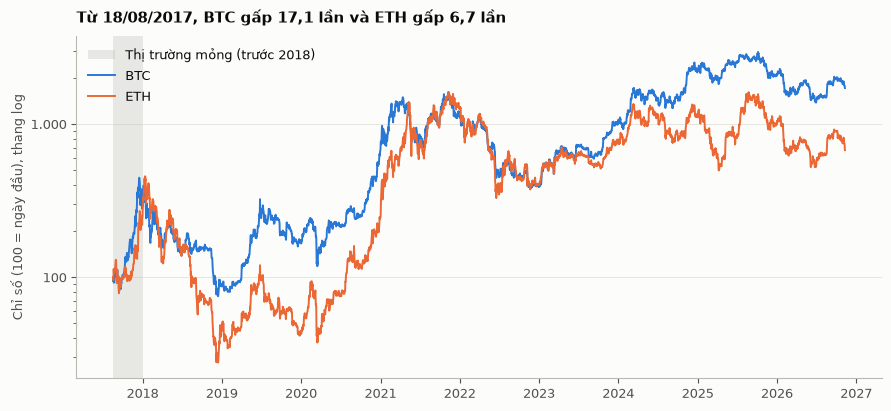

In [5]:
THIN_END = THIN.tz_convert(TZ).tz_localize(None)       # hết giai đoạn thị trường mỏng
first_year, last_year = px.index[0].year, px.index[-1].year   # hai năm đầu và cuối chưa đủ 12 tháng
ylab = lambda y: f"{y}*" if y in (first_year, last_year) else str(y)
def shade(ax, label=True):
    ax.axvspan(px.index[0], THIN_END, color=GREY, alpha=0.3, lw=0, label="Thị trường mỏng (trước 2018)" if label else None)

idxp = px / px.iloc[0] * 100
mult = idxp.iloc[-1] / 100     # chỉ số 100 = ngày đầu, nên chia 100 để ra số lần
fig, ax = plt.subplots(figsize=(9, 4.2))
shade(ax)
for s in SYMS:
    ax.plot(idxp.index, idxp[s], color=COL[s], lw=1.4, label=NAME[s])
ax.set_yscale("log"); ax.yaxis.set_major_formatter(fmt_int)
ax.set_ylabel("Chỉ số (100 = ngày đầu), thang log")
ttl(ax, f"Từ {dmy(px.index[0])}, BTC {times(mult['BTCUSDT'])} và ETH {times(mult['ETHUSDT'])}")
ax.legend(loc="upper left")
save(fig, "01_gia_chi_so")

Lợi suất năm        Biến động năm hoá       Sụt giảm tối đa trong năm      
               BTC    ETH               BTC   ETH                       BTC   ETH
2017*        +226%  +143%              121%  132%                      -37%  -39%
2018          -73%   -82%               85%  112%                      -81%  -94%
2019          +93%    -3%               68%   80%                      -51%  -65%
2020         +294%  +459%               67%   87%                      -52%  -60%
2021          +67%  +415%               87%  110%                      -53%  -58%
2022          -65%   -68%               60%   84%                      -66%  -74%
2023         +157%   +92%               45%   46%                      -20%  -27%
2024         +123%   +48%               49%   60%                      -26%  -44%
2025           -8%   -13%               40%   69%                      -33%  -60%
2026*         -17%   -32%               42%   57%                      -40%  -54%

* 2017: chỉ từ 18/08/2017. 2026: đến 10/11/2026. Hai năm này chưa đủ 12 tháng.


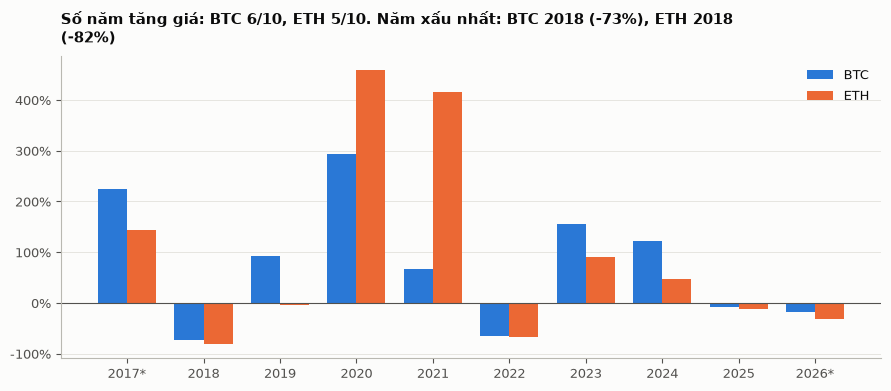

In [6]:
yr = px.copy(); yr["year"] = yr.index.year
ye = yr.groupby("year")[SYMS].last()
yret = ye.pct_change()
yret.iloc[0] = ye.iloc[0] / px.iloc[0] - 1
vol_y = daily.assign(year=daily["day"].dt.year).groupby(["year", "symbol"])["ret"].std().unstack()[SYMS] * np.sqrt(365)
def maxdd(s): return (s / s.cummax() - 1).min()
dd_y = yr.groupby("year")[SYMS].agg(maxdd)

tab = pd.DataFrame({
    ("Lợi suất năm", "BTC"): yret["BTCUSDT"].map(lambda v: vn(v, 0, pct=True, sign=True)),
    ("Lợi suất năm", "ETH"): yret["ETHUSDT"].map(lambda v: vn(v, 0, pct=True, sign=True)),
    ("Biến động năm hoá", "BTC"): vol_y["BTCUSDT"].map(lambda v: vn(v, 0, pct=True)),
    ("Biến động năm hoá", "ETH"): vol_y["ETHUSDT"].map(lambda v: vn(v, 0, pct=True)),
    ("Sụt giảm tối đa trong năm", "BTC"): dd_y["BTCUSDT"].map(lambda v: vn(v, 0, pct=True)),
    ("Sụt giảm tối đa trong năm", "ETH"): dd_y["ETHUSDT"].map(lambda v: vn(v, 0, pct=True)),
})
tab.index = [ylab(y) for y in tab.index]
display(tab)
print(f"* {first_year}: chỉ từ {dmy(px.index[0])}. {last_year}: đến {dmy(px.index[-1])}. Hai năm này chưa đủ 12 tháng.")

n = len(yret)
up = (yret > 0).sum()
worst = {s: (yret[s].idxmin(), yret[s].min()) for s in SYMS}
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.38; x = np.arange(n)
for i, s in enumerate(SYMS):
    ax.bar(x + (i - 0.5) * w, yret[s].values, w, color=COL[s], label=NAME[s])
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([ylab(y) for y in yret.index])
ax.yaxis.set_major_formatter(fmt_pct0); ax.grid(axis="x", visible=False)
ttl(ax, f"Số năm tăng giá: BTC {up['BTCUSDT']}/{n}, ETH {up['ETHUSDT']}/{n}. "
        f"Năm xấu nhất: BTC {worst['BTCUSDT'][0]} ({vn(worst['BTCUSDT'][1], 0, pct=True)}), "
        f"ETH {worst['ETHUSDT'][0]} ({vn(worst['ETHUSDT'][1], 0, pct=True)})")
ax.legend(loc="upper right")
save(fig, "02_loi_suat_nam")

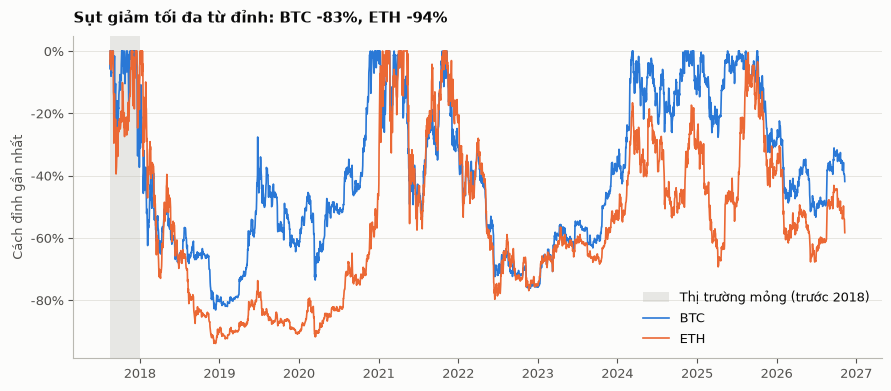

BTC: đỉnh 17/12/2017, đáy 15/12/2018 (-83%), hồi lại đỉnh cũ ngày 24/11/2020: 1.073 ngày kể từ đỉnh, 710 ngày kể từ đáy. Hiện cách đỉnh gần nhất -42%.
ETH: đỉnh 13/01/2018, đáy 15/12/2018 (-94%), hồi lại đỉnh cũ ngày 19/01/2021: 1.102 ngày kể từ đỉnh, 766 ngày kể từ đáy. Hiện cách đỉnh gần nhất -58%.


In [7]:
def dd_info(s):
    dd = s / s.cummax() - 1
    tr = dd.idxmin(); pk = s[:tr].idxmax()
    after = s[tr:][s[tr:] >= s[pk]]
    return dd.min(), pk, tr, (after.index[0] if len(after) else None), dd

info = {s: dd_info(px[s]) for s in SYMS}
fig, ax = plt.subplots(figsize=(9, 4))
shade(ax)
for s in SYMS:
    ax.plot(info[s][4].index, info[s][4], color=COL[s], lw=1.2, label=NAME[s])
ax.yaxis.set_major_formatter(fmt_pct0); ax.set_ylabel("Cách đỉnh gần nhất")
ttl(ax, f"Sụt giảm tối đa từ đỉnh: BTC {vn(info['BTCUSDT'][0], 0, pct=True)}, ETH {vn(info['ETHUSDT'][0], 0, pct=True)}")
ax.legend(loc="lower right")
save(fig, "03_drawdown")

for s in SYMS:
    mdd, pk, tr, rec, dd = info[s]
    dn = lambda n: f"{n:,}".replace(",", ".")
    hoi = (f"hồi lại đỉnh cũ ngày {dmy(rec)}: {dn((rec - pk).days)} ngày kể từ đỉnh, {dn((rec - tr).days)} ngày kể từ đáy"
           if rec is not None else "chưa hồi lại đỉnh cũ")
    print(f"{NAME[s]}: đỉnh {dmy(pk)}, đáy {dmy(tr)} ({vn(mdd, 0, pct=True)}), {hoi}. "
          f"Hiện cách đỉnh gần nhất {vn(dd.iloc[-1], 0, pct=True)}.")

## 4. Biến động theo thời gian

Câu hỏi 2. Biến động thực hiện là độ lệch chuẩn lăn 30 ngày của log-return ngày, nhân √365 để năm hoá. Phần này cũng dùng toàn bộ dữ liệu từ khi sàn mở. Hai kiểm tra bổ sung dùng return giờ: tự tương quan của return (có dự báo được chiều không) và của |return| (biến động có gom cụm không).

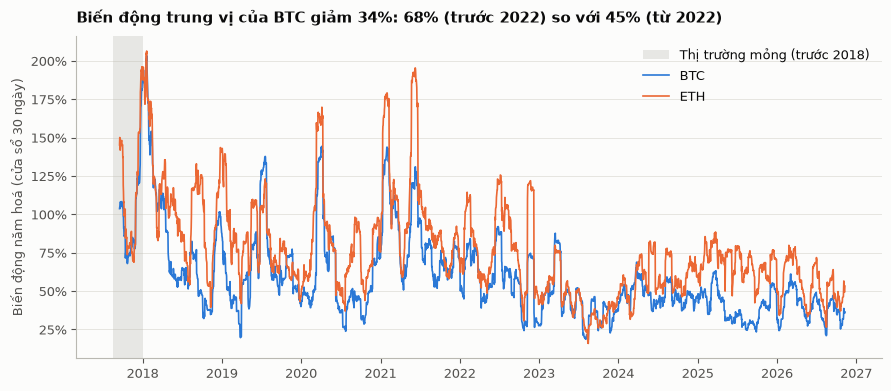

Biến động trung vị (trước 2022 → từ 2022): BTC 68% → 45%; ETH 88% → 59%


In [8]:
rv = dr.rolling(30).std() * np.sqrt(365)
split_d = SPLIT.tz_localize(None)
early, late = rv[rv.index < split_d].median(), rv[rv.index >= split_d].median()
fig, ax = plt.subplots(figsize=(9, 4))
shade(ax)
for s in SYMS:
    ax.plot(rv.index, rv[s], color=COL[s], lw=1.2, label=NAME[s])
ax.yaxis.set_major_formatter(fmt_pct0); ax.set_ylabel("Biến động năm hoá (cửa sổ 30 ngày)")
chg = late["BTCUSDT"] / early["BTCUSDT"] - 1
ttl(ax, f"Biến động trung vị của BTC {'giảm' if chg < 0 else 'tăng'} {vn(abs(chg), 0, pct=True)}: "
        f"{vn(early['BTCUSDT'], 0, pct=True)} (trước 2022) so với {vn(late['BTCUSDT'], 0, pct=True)} (từ 2022)")
ax.legend(loc="upper right")
save(fig, "04_bien_dong_lang")
print("Biến động trung vị (trước 2022 → từ 2022):", "; ".join(f"{NAME[s]} {vn(early[s], 0, pct=True)} → {vn(late[s], 0, pct=True)}" for s in SYMS))

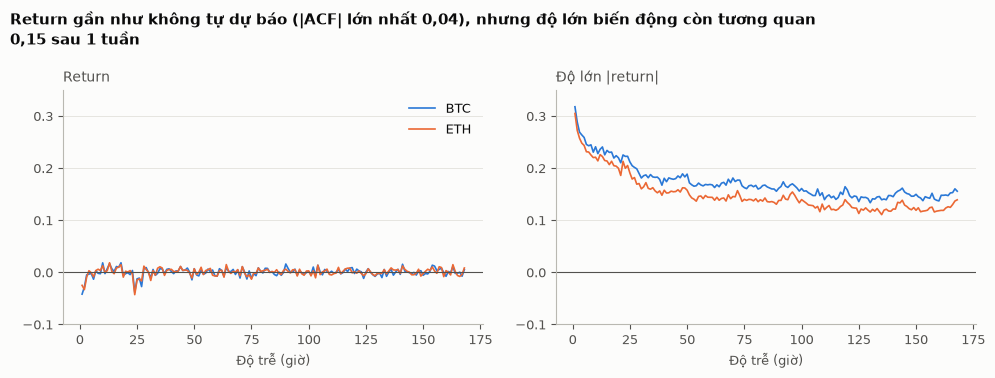

ACF lag 1 của return: BTC -0,042, ETH -0,025
ACF lag 1 của |return|: BTC 0,318, ETH 0,305; lag 24: BTC 0,223


In [9]:
LAGS = np.arange(1, 169)
ret_h = df.pivot(index="open_time", columns="symbol", values="ret_1h")[SYMS]
acf_r = pd.DataFrame({s: [ret_h[s].autocorr(k) for k in LAGS] for s in SYMS}, index=LAGS)
acf_a = pd.DataFrame({s: [ret_h[s].abs().autocorr(k) for k in LAGS] for s in SYMS}, index=LAGS)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for ax, a, t in zip(axes, [acf_r, acf_a], ["Return", "Độ lớn |return|"]):
    for s in SYMS:
        ax.plot(a.index, a[s], color=COL[s], lw=1.2, label=NAME[s])
    ax.axhline(0, color=INK2, lw=0.8); ax.set_xlabel("Độ trễ (giờ)"); ax.set_title(t, loc="left", fontsize=10, color=INK2)
    ax.set_ylim(-0.1, 0.35)
axes[0].legend(loc="upper right")
fig.suptitle(textwrap.fill(f"Return gần như không tự dự báo (|ACF| lớn nhất {vn(acf_r.abs().max().max(), 2)}), nhưng độ lớn biến động còn tương quan {vn(acf_a.loc[168].mean(), 2)} sau 1 tuần", 95),
             x=0.01, ha="left", fontsize=11, fontweight="bold")
save(fig, "05_acf")
print(f"ACF lag 1 của return: BTC {vn(acf_r.loc[1,'BTCUSDT'],3)}, ETH {vn(acf_r.loc[1,'ETHUSDT'],3)}")
print(f"ACF lag 1 của |return|: BTC {vn(acf_a.loc[1,'BTCUSDT'],3)}, ETH {vn(acf_a.loc[1,'ETHUSDT'],3)}; lag 24: BTC {vn(acf_a.loc[24,'BTCUSDT'],3)}")

## 5. Phân bố return và rủi ro đuôi

Return mỗi giờ được chuẩn hoá về z-score để so với phân phối chuẩn. Phân phối chuẩn dự đoán chỉ khoảng 0,27% số giờ nằm ngoài ±3 độ lệch chuẩn. Nếu thực tế cao hơn nhiều, các mô hình giả định chuẩn sẽ đánh giá thấp rủi ro.

,số giờ,trung bình (điểm cơ bản),độ lệch chuẩn,độ lệch (skew),độ nhọn dư,ngoài ±3σ,nhỏ nhất,lớn nhất
mã,,,,,,,,
BTC,80.800,"0,34","0,0076","-0,47","37,1","1,95%","-20,103%","16,028%"
ETH,80.800,"0,23","0,0095","-0,57","28,4","1,87%","-23,411%","16,619%"


Phân phối chuẩn: 0,27% số giờ nằm ngoài ±3σ.


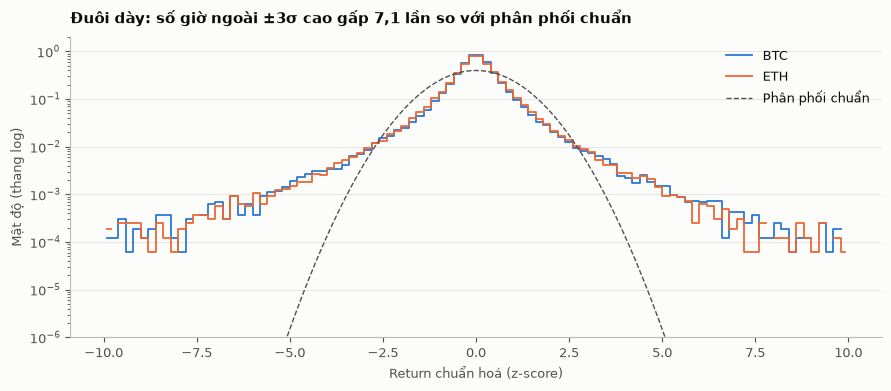

In [10]:
rows, Z = [], {}
for s in SYMS:
    r = ret_h[s].dropna(); z = (r - r.mean()) / r.std(); Z[s] = z
    rows.append({"mã": NAME[s], "số giờ": f"{len(r):,}".replace(",", "."), "trung bình (điểm cơ bản)": vn(r.mean() * 1e4, 2),
                 "độ lệch chuẩn": vn(r.std(), 4), "độ lệch (skew)": vn(r.skew(), 2), "độ nhọn dư": vn(r.kurt(), 1),
                 "ngoài ±3σ": vn((z.abs() > 3).mean(), 2, pct=True), "nhỏ nhất": vn(r.min(), 3, pct=True), "lớn nhất": vn(r.max(), 3, pct=True)})
display(pd.DataFrame(rows).set_index("mã"))
p3 = 2 * (1 - stats.norm.cdf(3))
print(f"Phân phối chuẩn: {vn(p3, 2, pct=True)} số giờ nằm ngoài ±3σ.")

bins = np.linspace(-10, 10, 101); mid = (bins[1:] + bins[:-1]) / 2
fig, ax = plt.subplots(figsize=(9, 4))
for s in SYMS:
    h, _ = np.histogram(Z[s], bins=bins, density=True)
    ax.step(mid, np.where(h > 0, h, np.nan), where="mid", color=COL[s], lw=1.3, label=NAME[s])
ax.plot(mid, stats.norm.pdf(mid), color=INK2, lw=1, ls="--", label="Phân phối chuẩn")
ax.set_yscale("log"); ax.set_ylim(1e-6, 2); ax.set_xlabel("Return chuẩn hoá (z-score)"); ax.set_ylabel("Mật độ (thang log)")
ratio = np.mean([(Z[s].abs() > 3).mean() for s in SYMS]) / p3
ttl(ax, f"Đuôi dày: số giờ ngoài ±3σ cao gấp {vn(ratio, 1)} lần so với phân phối chuẩn")
ax.legend(loc="upper right")
save(fig, "06_phan_bo_return")

## 6. Mùa vụ theo giờ và theo thứ

Câu hỏi 3. Mùa vụ được tách thành hai phần: độ lớn biến động (|return|) và chiều của lợi suất (return có dấu). Với độ lớn, chỉ số mùa vụ là |return| trung bình của từng giờ chia cho |return| trung bình cả mã, nên 1,00 là mức trung bình. Kruskal–Wallis kiểm định sự khác biệt giữa 24 giờ, kèm ε² làm độ lớn hiệu ứng. Với chiều lợi suất, kiểm định t từng giờ và hiệu chỉnh Bonferroni (24 phép thử).

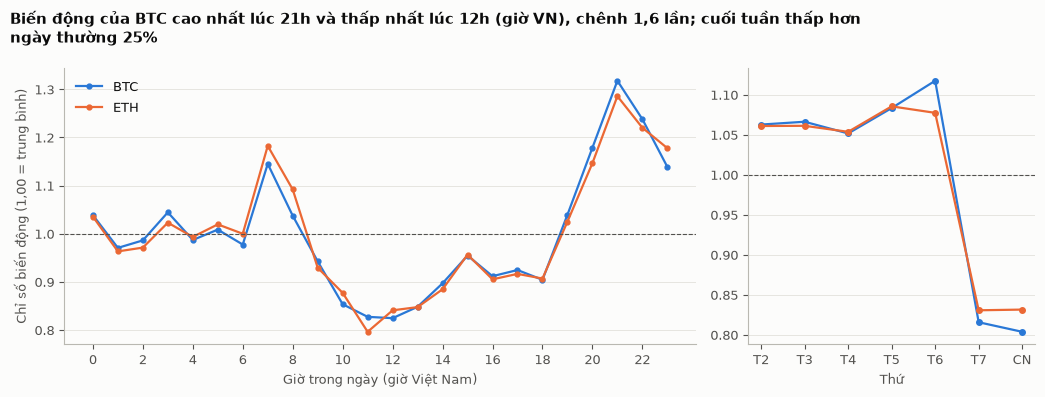

,H,p,ε²
symbol,,,
BTC,1.058,"< 0,001","0,013"
ETH,1.053,"< 0,001","0,013"


BTC: giờ sôi động nhất 21h (chỉ số 1,32), giờ yên tĩnh nhất 12h (chỉ số 0,82); Thứ 7/CN so với T2-T6: -25%
ETH: giờ sôi động nhất 21h (chỉ số 1,29), giờ yên tĩnh nhất 11h (chỉ số 0,80); Thứ 7/CN so với T2-T6: -22%
ε² nhỏ vì kiểm định dùng hạng của từng giờ rất nhiễu, nhưng chênh lệch thực tế giữa giờ mạnh nhất và yếu nhất vẫn lên tới 1,6 lần ở BTC.


In [11]:
h = df.dropna(subset=["ret_1h"]).copy()
h["ar"] = h["ret_1h"].abs()
mean_ar = h.groupby("symbol")["ar"].mean()
prof_h = h.groupby(["hour", "symbol"])["ar"].mean().unstack()[SYMS] / mean_ar[SYMS]
prof_d = h.groupby(["dow", "symbol"])["ar"].mean().unstack()[SYMS] / mean_ar[SYMS]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4), gridspec_kw={"width_ratios": [2.2, 1]})
for s in SYMS:
    axes[0].plot(prof_h.index, prof_h[s], color=COL[s], lw=1.6, marker="o", ms=3.5, label=NAME[s])
    axes[1].plot(prof_d.index, prof_d[s], color=COL[s], lw=1.6, marker="o", ms=4)
axes[0].axhline(1, color=INK2, lw=0.8, ls="--")
axes[0].set_xticks(range(0, 24, 2)); axes[0].set_xlabel("Giờ trong ngày (giờ Việt Nam)")
axes[1].axhline(1, color=INK2, lw=0.8, ls="--")
axes[1].set_xticks(range(7)); axes[1].set_xticklabels(DOW); axes[1].set_xlabel("Thứ")
axes[0].set_ylabel("Chỉ số biến động (1,00 = trung bình)"); axes[0].legend(loc="upper left")
pk, tr = prof_h["BTCUSDT"].idxmax(), prof_h["BTCUSDT"].idxmin()
we_ratio = prof_d["BTCUSDT"].loc[5:6].mean() / prof_d["BTCUSDT"].loc[0:4].mean() - 1
fig.suptitle(textwrap.fill(f"Biến động của BTC cao nhất lúc {pk}h và thấp nhất lúc {tr}h (giờ VN), chênh {vn(prof_h['BTCUSDT'].max()/prof_h['BTCUSDT'].min(), 1)} lần; "
                           f"cuối tuần {'thấp hơn' if we_ratio < 0 else 'cao hơn'} ngày thường {vn(abs(we_ratio), 0, pct=True)}", 100),
             x=0.01, ha="left", fontsize=11, fontweight="bold")
save(fig, "07_mua_vu_bien_dong")

def kw(g):
    groups = [x.values for _, x in g.groupby("hour")["ar"]]
    H, p = stats.kruskal(*groups)
    return pd.Series({"H": H, "p": p, "eps2": H / (len(g) - 1)})
kwr = h.groupby("symbol").apply(kw).loc[SYMS]
display(pd.DataFrame({"H": kwr["H"].map(lambda v: vn(v, 0)),
                      "p": kwr["p"].map(lambda v: "< 0,001" if v < 0.001 else vn(v, 3)),
                      "ε²": kwr["eps2"].map(lambda v: vn(v, 3))}).rename(index=NAME))
for s in SYMS:
    print(f"{NAME[s]}: giờ sôi động nhất {prof_h[s].idxmax()}h (chỉ số {vn(prof_h[s].max(), 2)}), "
          f"giờ yên tĩnh nhất {prof_h[s].idxmin()}h (chỉ số {vn(prof_h[s].min(), 2)}); "
          f"Thứ 7/CN so với T2-T6: {vn(prof_d[s].loc[5:6].mean() / prof_d[s].loc[0:4].mean() - 1, 0, pct=True, sign=True)}")
print("ε² nhỏ vì kiểm định dùng hạng của từng giờ rất nhiễu, nhưng chênh lệch thực tế giữa giờ mạnh nhất và yếu nhất vẫn lên tới "
      f"{vn(prof_h['BTCUSDT'].max()/prof_h['BTCUSDT'].min(), 1)} lần ở BTC.")

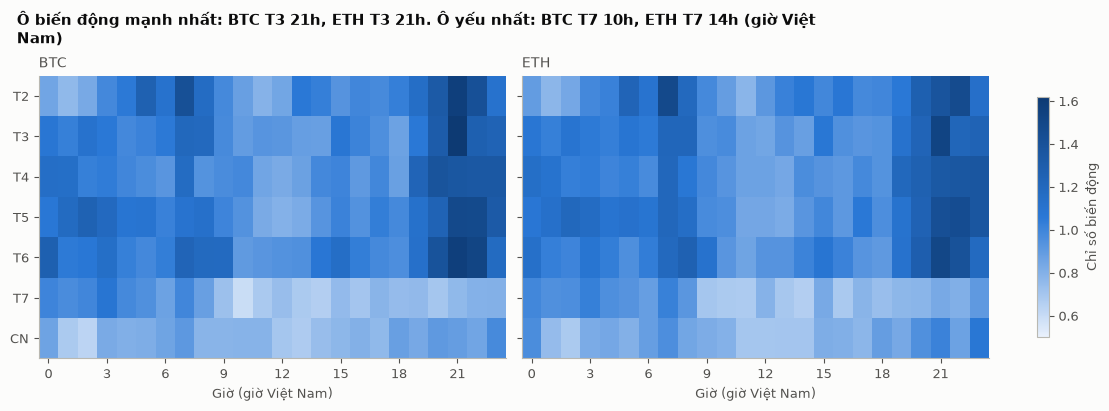

In [12]:
hm = h.groupby(["symbol", "dow", "hour"])["ar"].mean().unstack(["symbol"])
cmap = LinearSegmentedColormap.from_list("blue", ["#e9f1fc", "#2a78d6", "#0d3a73"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, constrained_layout=True)
vmax = max((hm[s] / mean_ar[s]).max().max() for s in SYMS)
for ax, s in zip(axes, SYMS):
    m = (hm[s].unstack("hour") / mean_ar[s]).values
    im = ax.imshow(m, aspect="auto", cmap=cmap, vmin=0.5, vmax=vmax)
    ax.set_xticks(range(0, 24, 3)); ax.set_yticks(range(7)); ax.set_yticklabels(DOW)
    ax.set_title(NAME[s], loc="left", fontsize=10, color=INK2); ax.set_xlabel("Giờ (giờ Việt Nam)"); ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.85, label="Chỉ số biến động")
top = {s: hm[s].idxmax() for s in SYMS}; bot = {s: hm[s].idxmin() for s in SYMS}
cell = lambda d: ", ".join(f"{NAME[s]} {DOW[d[s][0]]} {d[s][1]}h" for s in SYMS)
fig.suptitle(textwrap.fill(f"Ô biến động mạnh nhất: {cell(top)}. Ô yếu nhất: {cell(bot)} (giờ Việt Nam)", 95),
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.savefig(FIG / "08_heatmap_gio_thu.png", dpi=150, facecolor=BG, bbox_inches="tight"); plt.show()

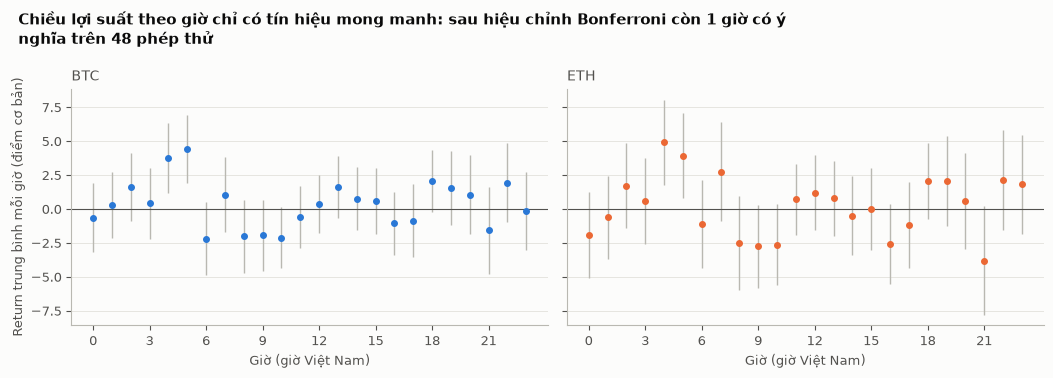

Số giờ có p < 0,05 (chưa hiệu chỉnh): {'BTC': 2, 'ETH': 2} | sau Bonferroni: {'BTC': 1, 'ETH': 0}
44/48 khoảng tin cậy 95% chứa 0. Số giờ có p < 0,05 ở mức chưa hiệu chỉnh (4) gần với số kỳ vọng do ngẫu nhiên (48 × 5% = 2,4).
Giờ vượt ngưỡng sau Bonferroni: {'BTC 5h': '+4,4 điểm cơ bản, p hiệu chỉnh 0,012'}
Chỉ tính từ 2018: 0 giờ có ý nghĩa sau Bonferroni. Tín hiệu còn lại khi gộp 2017 không có ở giai đoạn sau, nên được coi là mong manh.


In [13]:
res = []
for s in SYMS:
    g = h[h["symbol"] == s].groupby("hour")["ret_1h"]
    m, se = g.mean(), g.sem()
    p = g.apply(lambda v: stats.ttest_1samp(v, 0).pvalue)
    res.append(pd.DataFrame({"s": s, "mean_bp": m * 1e4, "ci_bp": 1.96 * se * 1e4, "p": p, "p_bonf": (p * 24).clip(upper=1)}))
res = pd.concat(res)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, s in zip(axes, SYMS):
    r = res[res["s"] == s]
    ax.errorbar(r.index, r["mean_bp"], yerr=r["ci_bp"], fmt="o", ms=4, color=COL[s], ecolor=GREY, elinewidth=1, capsize=0)
    ax.axhline(0, color=INK2, lw=0.8); ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Giờ (giờ Việt Nam)")
    ax.set_title(NAME[s], loc="left", fontsize=10, color=INK2)
axes[0].set_ylabel("Return trung bình mỗi giờ (điểm cơ bản)")
nraw = res.groupby("s")["p"].apply(lambda v: int((v < 0.05).sum()))
nbon = res.groupby("s")["p_bonf"].apply(lambda v: int((v < 0.05).sum()))
n_ci = int(((res["mean_bp"] - res["ci_bp"] <= 0) & (res["mean_bp"] + res["ci_bp"] >= 0)).sum())
fig.suptitle(textwrap.fill(f"Chiều lợi suất theo giờ {'không có tín hiệu' if nbon.sum() == 0 else 'chỉ có tín hiệu mong manh'}: sau hiệu chỉnh Bonferroni còn {nbon.sum()} giờ có ý nghĩa trên 48 phép thử", 95),
             x=0.01, ha="left", fontsize=11, fontweight="bold")
save(fig, "09_return_theo_gio")
print("Số giờ có p < 0,05 (chưa hiệu chỉnh):", {NAME[k]: int(v) for k, v in nraw.items()}, "| sau Bonferroni:", {NAME[k]: int(v) for k, v in nbon.items()})
print(f"{n_ci}/48 khoảng tin cậy 95% chứa 0. Số giờ có p < 0,05 ở mức chưa hiệu chỉnh ({nraw.sum()}) gần với số kỳ vọng do ngẫu nhiên (48 × 5% = 2,4).")
sig_hours = res[res["p_bonf"] < 0.05]
sig18 = 0
for s in SYMS:
    g18 = h[(h["symbol"] == s) & (h["open_time"] >= THIN)].groupby("hour")["ret_1h"]
    sig18 += int((g18.apply(lambda v: stats.ttest_1samp(v, 0).pvalue) * 24 < 0.05).sum())
if len(sig_hours):
    print("Giờ vượt ngưỡng sau Bonferroni:", {f"{NAME[r['s']]} {i}h": f"{r['mean_bp']:+.1f} điểm cơ bản, p hiệu chỉnh {r['p_bonf']:.3f}".replace('.', ',') for i, r in sig_hours.iterrows()})
print(f"Chỉ tính từ 2018: {sig18} giờ có ý nghĩa sau Bonferroni. Tín hiệu còn lại khi gộp 2017 không có ở giai đoạn sau, nên được coi là mong manh.")

## 7. Quan hệ BTC và ETH

Câu hỏi 4. Tương quan tính trên log-return, theo giờ và theo ngày. Hệ số beta (độ dốc hồi quy return ETH theo return BTC) cho biết ETH khuếch đại biến động của BTC bao nhiêu lần. Beta được so giữa giờ thường và 1% giờ có BTC biến động mạnh nhất; dùng beta thay cho tương quan vì lọc theo độ lớn của BTC sẽ làm giảm tương quan một cách cơ học. Sau đó một bản đồ nhiệt tổng hợp hai thứ: ma trận tương quan Spearman giữa các biến theo ngày (return, độ lớn return, khối lượng tương đối, tỉ lệ mua chủ động của cả hai mã), và tương quan Pearson BTC–ETH theo từng năm ở ba tần suất (giờ, ngày, tuần) để xem mối liên hệ có ổn định không.

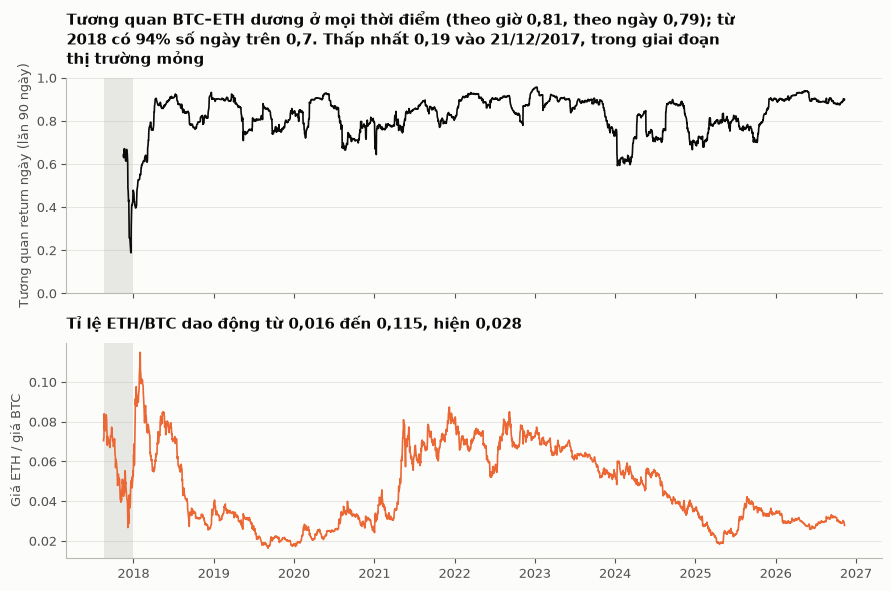

Beta ETH theo BTC: toàn bộ 1,00; giờ thường 1,03; 1% giờ BTC biến động mạnh nhất 0,96
Tương quan return ngày theo năm: 2017: 0,57; 2018: 0,80; 2019: 0,80; 2020: 0,84; 2021: 0,82; 2022: 0,90; 2023: 0,87; 2024: 0,75; 2025: 0,80; 2026: 0,91


In [14]:
lr = ret_h.dropna()
corr_h = lr.corr().iloc[0, 1]; corr_d = dr.corr().iloc[0, 1]
beta = lambda x: x.cov().iloc[0, 1] / x["BTCUSDT"].var()
q = lr["BTCUSDT"].abs().quantile(0.99)
beta_all, beta_tail, beta_rest = beta(lr), beta(lr[lr["BTCUSDT"].abs() >= q]), beta(lr[lr["BTCUSDT"].abs() < q])
by_year = dr.groupby(dr.index.year).apply(lambda x: x.corr().iloc[0, 1])
roll = dr["BTCUSDT"].rolling(90).corr(dr["ETHUSDT"])
ratio = px["ETHUSDT"] / px["BTCUSDT"]

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for ax_ in axes:
    ax_.axvspan(px.index[0], THIN_END, color=GREY, alpha=0.3, lw=0)
axes[0].plot(roll.index, roll, color=INK, lw=1.2)
axes[0].set_ylim(0, 1); axes[0].set_ylabel("Tương quan return ngày (lăn 90 ngày)")
share70 = (roll[roll.index >= THIN_END].dropna() >= 0.7).mean()
ttl(axes[0], f"Tương quan BTC–ETH dương ở mọi thời điểm (theo giờ {vn(corr_h, 2)}, theo ngày {vn(corr_d, 2)}); từ 2018 có {vn(share70, 0, pct=True)} số ngày trên 0,7. "
             f"Thấp nhất {vn(roll.min(), 2)} vào {dmy(roll.idxmin())}{', trong giai đoạn thị trường mỏng' if roll.idxmin() < THIN_END else ''}")
axes[1].plot(ratio.index, ratio, color=COL["ETHUSDT"], lw=1.2)
axes[1].set_ylabel("Giá ETH / giá BTC")
ttl(axes[1], f"Tỉ lệ ETH/BTC dao động từ {vn(ratio.min(), 3)} đến {vn(ratio.max(), 3)}, hiện {vn(ratio.iloc[-1], 3)}")
save(fig, "10_btc_eth")
print(f"Beta ETH theo BTC: toàn bộ {vn(beta_all, 2)}; giờ thường {vn(beta_rest, 2)}; 1% giờ BTC biến động mạnh nhất {vn(beta_tail, 2)}")
print("Tương quan return ngày theo năm:", "; ".join(f"{int(k)}: {vn(v, 2)}" for k, v in by_year.items()))

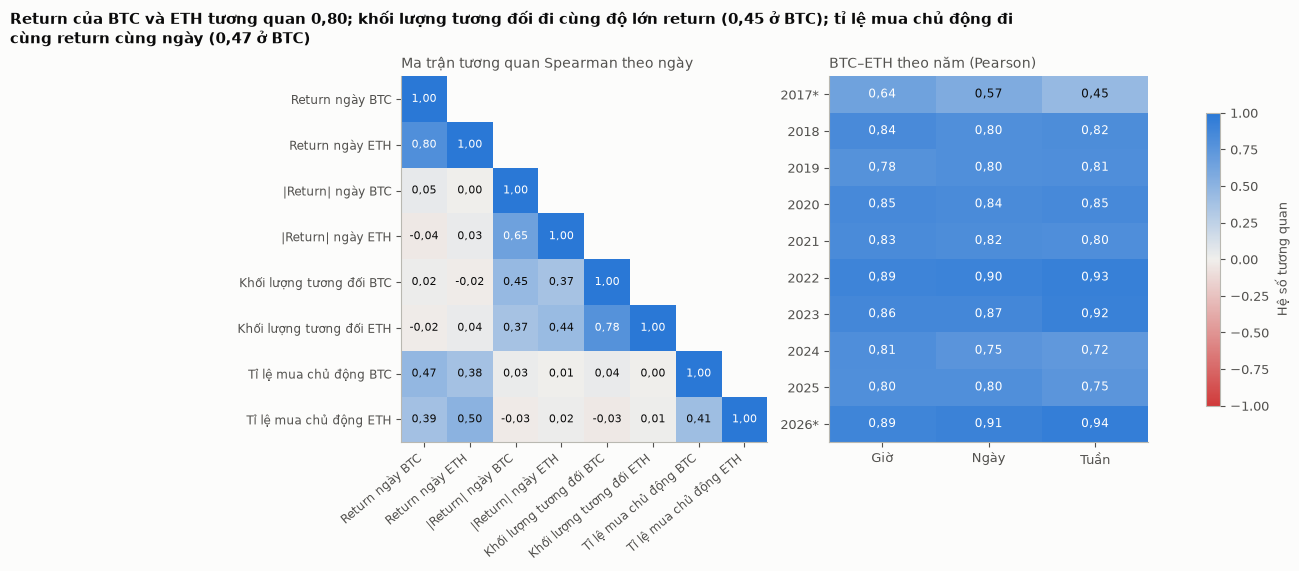

Return ngày BTC–ETH: Spearman 0,80, Pearson 0,79.
Tương quan theo tuần mỗi năm dựa trên khoảng 52 tuần (năm đầu 19, năm cuối 46 tuần), nên dao động hơn hai tần suất còn lại.
Tương quan theo năm: giờ 0,64–0,89, ngày 0,57–0,91, tuần 0,45–0,94.


In [15]:
    # Bản đồ nhiệt tương quan: (trái) ma trận Spearman các biến theo ngày; (phải) tương quan Pearson BTC–ETH theo năm và tần suất
dm = daily.copy()
dm["tbr"] = dm["tbq"] / dm["qv"]
dm["rel_vol"] = dm["qv"] / dm.groupby("symbol")["qv"].transform(lambda s: s.rolling(30).median().shift(1))
dm["abs_ret"] = dm["ret"].abs()
labels = {"ret": "Return ngày", "abs_ret": "|Return| ngày", "rel_vol": "Khối lượng tương đối", "tbr": "Tỉ lệ mua chủ động"}
wide = dm.pivot(index="day", columns="symbol", values=list(labels))
wide.columns = [f"{labels[v]} {NAME[s]}" for v, s in wide.columns]
order = [f"{labels[v]} {NAME[s]}" for v in labels for s in SYMS]
cm = wide[order].dropna().corr(method="spearman")

lr_h = ret_h.dropna()
wk = np.log(px.resample("W").last()).diff().dropna()
corr_by = lambda x: x.corr().iloc[0, 1]
yc = pd.DataFrame({"Giờ": lr_h.groupby(lr_h.index.year).apply(corr_by),
                   "Ngày": dr.groupby(dr.index.year).apply(corr_by),
                   "Tuần": wk.groupby(wk.index.year).apply(corr_by)})

cmap_div = LinearSegmentedColormap.from_list("div", ["#d03b3b", "#f0efec", "#2a78d6"])   # đỏ - xám - xanh, tâm xám là 0
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={"width_ratios": [2.4, 1]}, constrained_layout=True)
n = len(order)
M = np.ma.array(cm.values, mask=np.triu(np.ones((n, n), bool), k=1))
ax = axes[0]
im = ax.imshow(M, cmap=cmap_div, vmin=-1, vmax=1)
ax.set_xticks(range(n)); ax.set_yticks(range(n)); ax.grid(False)
ax.set_xticklabels(order, rotation=40, ha="right", fontsize=8.5); ax.set_yticklabels(order, fontsize=8.5)
for i in range(n):
    for j in range(i + 1):
        v = cm.values[i, j]
        ax.text(j, i, vn(v, 2), ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 else INK)
ax.set_title("Ma trận tương quan Spearman theo ngày", loc="left", fontsize=10, color=INK2)

ax2 = axes[1]
ax2.imshow(yc.values, cmap=cmap_div, vmin=-1, vmax=1, aspect="auto"); ax2.grid(False)
ax2.set_xticks(range(3)); ax2.set_xticklabels(yc.columns); ax2.set_yticks(range(len(yc))); ax2.set_yticklabels([ylab(y) for y in yc.index])
for i in range(len(yc)):
    for j in range(3):
        v = yc.values[i, j]
        ax2.text(j, i, vn(v, 2), ha="center", va="center", fontsize=8.5, color="white" if abs(v) > 0.6 else INK)
ax2.set_title("BTC–ETH theo năm (Pearson)", loc="left", fontsize=10, color=INK2)
fig.colorbar(im, ax=axes, shrink=0.8, label="Hệ số tương quan")
a, b_, c_ = (cm.loc["Return ngày BTC", "Return ngày ETH"], cm.loc["|Return| ngày BTC", "Khối lượng tương đối BTC"],
             cm.loc["Return ngày BTC", "Tỉ lệ mua chủ động BTC"])
fig.suptitle(textwrap.fill(f"Return của BTC và ETH tương quan {vn(a, 2)}; khối lượng tương đối đi cùng độ lớn return ({vn(b_, 2)} ở BTC); "
                           f"tỉ lệ mua chủ động đi cùng return cùng ngày ({vn(c_, 2)} ở BTC)", 120), x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.savefig(FIG / "10b_ma_tran_tuong_quan.png", dpi=150, facecolor=BG, bbox_inches="tight"); plt.show()

print(f"Return ngày BTC–ETH: Spearman {vn(a, 2)}, Pearson {vn(corr_d, 2)}.")
nw = wk.groupby(wk.index.year).size()
print(f"Tương quan theo tuần mỗi năm dựa trên khoảng {int(nw.median())} tuần (năm đầu {int(nw.iloc[0])}, năm cuối {int(nw.iloc[-1])} tuần), nên dao động hơn hai tần suất còn lại.")
print(f"Tương quan theo năm: giờ {vn(yc['Giờ'].min(), 2)}–{vn(yc['Giờ'].max(), 2)}, ngày {vn(yc['Ngày'].min(), 2)}–{vn(yc['Ngày'].max(), 2)}, tuần {vn(yc['Tuần'].min(), 2)}–{vn(yc['Tuần'].max(), 2)}.")

## 8. Khối lượng và dòng lệnh chủ động mua

Câu hỏi 5. Có ba việc cần kiểm tra. Thứ nhất là xu hướng của giá trị giao dịch theo tháng. Thứ hai là quan hệ giữa khối lượng tương đối (so với trung vị 30 ngày trước đó, để loại ảnh hưởng của giá tăng) và độ lớn biến động ngày. Thứ ba là tỉ lệ mua chủ động (`taker_buy_quote / quote_volume`) có dự báo return của giờ kế tiếp không, so với quan hệ cùng giờ.

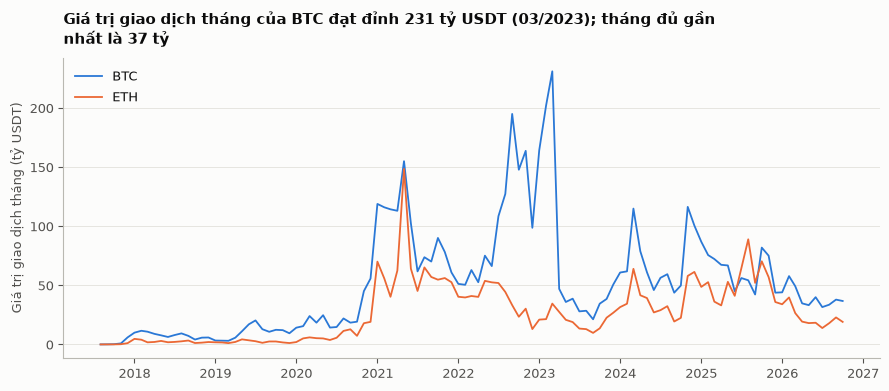

Bỏ tháng cuối (2026-11) vì chưa đủ ngày. ETH: đỉnh 148 tỷ (05/2021).
Sau đỉnh 03/2023, giá trị giao dịch BTC tháng kế tiếp thay đổi -80%. Đỉnh khối lượng và bước sụt đột ngột này không trùng đỉnh giá (xem biểu đồ 01), nên giả thuyết là chính sách phí hoặc khuyến mãi của sàn có ảnh hưởng. Giả thuyết cần đối chiếu nguồn ngoài; trước khi kiểm chứng, giá trị giao dịch tuyệt đối không nên dùng làm thước đo độ nóng của thị trường.


In [16]:
mv = df.groupby(["ym", "symbol"])["quote_volume"].sum().unstack()[SYMS] / 1e9
mv = mv.iloc[:-1]      # bỏ tháng cuối vì chưa đủ ngày
fig, ax = plt.subplots(figsize=(9, 4))
for s in SYMS:
    ax.plot(mv.index.to_timestamp(), mv[s], color=COL[s], lw=1.3, label=NAME[s])
ax.set_ylabel("Giá trị giao dịch tháng (tỷ USDT)"); ax.yaxis.set_major_formatter(fmt_int)
pm = mv["BTCUSDT"].idxmax()
ttl(ax, f"Giá trị giao dịch tháng của BTC đạt đỉnh {vn(mv['BTCUSDT'].max(), 0)} tỷ USDT ({pm.strftime('%m/%Y')}); tháng đủ gần nhất là {vn(mv['BTCUSDT'].iloc[-1], 0)} tỷ")
ax.legend(loc="upper left")
save(fig, "11_gia_tri_giao_dich")
print(f"Bỏ tháng cuối ({df['ym'].max()}) vì chưa đủ ngày. ETH: đỉnh {vn(mv['ETHUSDT'].max(), 0)} tỷ ({mv['ETHUSDT'].idxmax().strftime('%m/%Y')}).")
nxt = mv["BTCUSDT"].shift(-1).loc[pm] / mv["BTCUSDT"].loc[pm] - 1
print(f"Sau đỉnh {pm.strftime('%m/%Y')}, giá trị giao dịch BTC tháng kế tiếp thay đổi {vn(nxt, 0, pct=True, sign=True)}. "
      "Đỉnh khối lượng và bước sụt đột ngột này không trùng đỉnh giá (xem biểu đồ 01), nên giả thuyết là chính sách phí hoặc khuyến mãi của sàn "
      "có ảnh hưởng. Giả thuyết cần đối chiếu nguồn ngoài; trước khi kiểm chứng, giá trị giao dịch tuyệt đối không nên dùng làm thước đo độ nóng của thị trường.")

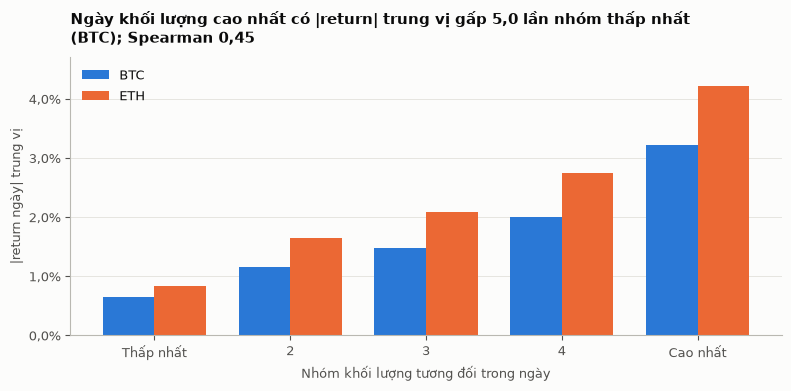

Spearman (khối lượng tương đối, |return ngày|): BTC 0,45; ETH 0,44 | số ngày: {'BTC': 3342, 'ETH': 3342}


In [17]:
dv = daily.copy()
dv["rel_vol"] = dv["qv"] / dv.groupby("symbol")["qv"].transform(lambda s: s.rolling(30).median().shift(1))
dv["abs_ret"] = dv["ret"].abs()
dv = dv.dropna(subset=["rel_vol", "abs_ret"])
dv["q"] = dv.groupby("symbol")["rel_vol"].transform(lambda s: pd.qcut(s, 5, labels=False))
qt = dv.groupby(["q", "symbol"])["abs_ret"].median().unstack()[SYMS]
rho_v = {s: stats.spearmanr(dv.loc[dv["symbol"] == s, "rel_vol"], dv.loc[dv["symbol"] == s, "abs_ret"])[0] for s in SYMS}

fig, ax = plt.subplots(figsize=(8, 4))
w = 0.38; x = np.arange(5)
for i, s in enumerate(SYMS):
    ax.bar(x + (i - 0.5) * w, qt[s].values, w, color=COL[s], label=NAME[s])
ax.set_xticks(x); ax.set_xticklabels(["Thấp nhất", "2", "3", "4", "Cao nhất"]); ax.set_xlabel("Nhóm khối lượng tương đối trong ngày"); ax.set_ylim(0, qt.max().max() * 1.12)
ax.set_ylabel("|return ngày| trung vị"); ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: vn(v, 1, pct=True))); ax.grid(axis="x", visible=False)
ttl(ax, f"Ngày khối lượng cao nhất có |return| trung vị gấp {vn(qt['BTCUSDT'].iloc[-1] / qt['BTCUSDT'].iloc[0], 1)} lần nhóm thấp nhất (BTC); Spearman {vn(rho_v['BTCUSDT'], 2)}")
ax.legend(loc="upper left")
save(fig, "12_khoi_luong_bien_dong")
print("Spearman (khối lượng tương đối, |return ngày|):", "; ".join(f"{NAME[s]} {vn(v, 2)}" for s, v in rho_v.items()), "| số ngày:", {NAME[k]: int(v) for k, v in dv.groupby("symbol").size().items()})

Kiểm tra độ trễ. Quan hệ ở trên là cùng ngày, nên chưa nói được khối lượng có báo trước biến động hay không. Ô dưới xét khối lượng của hôm nay với độ lớn biến động của ngày mai, rồi loại ảnh hưởng của biến động hôm nay (biến động vốn gom cụm: hôm nay mạnh thì mai thường mạnh) để xem khối lượng còn thêm được thông tin gì. Kết quả trong ô này chạy trên dữ liệu đến 05/11/2026; chạy lại notebook để cập nhật theo mốc dữ liệu mới.

In [18]:
# Khối lượng hôm nay có báo trước độ lớn biến động ngày mai không? (Spearman, ngày liền nhau trong từng mã)
lagrows = []
for s in SYMS:
    g = dv[dv["symbol"] == s].sort_index().copy()
    g["abs_ret_next"] = g["abs_ret"].shift(-1)
    g = g.dropna(subset=["abs_ret_next"])
    r_next = stats.spearmanr(g["rel_vol"], g["abs_ret_next"])[0]
    r_self = stats.spearmanr(g["abs_ret"], g["abs_ret_next"])[0]
    rk = g[["rel_vol", "abs_ret", "abs_ret_next"]].rank()
    resid = lambda y: y - np.polyval(np.polyfit(rk["abs_ret"], y, 1), rk["abs_ret"])
    r_part = np.corrcoef(resid(rk["rel_vol"]), resid(rk["abs_ret_next"]))[0, 1]
    lagrows.append({"mã": NAME[s], "khối lượng hôm nay → |return| ngày mai": vn(r_next, 2),
                    "|return| hôm nay → |return| ngày mai": vn(r_self, 2),
                    "khối lượng hôm nay → |return| ngày mai, đã loại |return| hôm nay": vn(r_part, 2)})
display(pd.DataFrame(lagrows).set_index("mã"))
print("Số ngày:", {NAME[k]: int(v) for k, v in dv.groupby("symbol").size().items()})

,khối lượng hôm nay → |return| ngày mai,|return| hôm nay → |return| ngày mai,"khối lượng hôm nay → |return| ngày mai, đã loại |return| hôm nay"
mã,,,
BTC,"0,13","0,24","0,03"
ETH,"0,13","0,20","0,05"


Số ngày: {'BTC': 3342, 'ETH': 3342}


Khối lượng hôm nay chỉ liên hệ yếu với biến động ngày mai (khoảng 0,13), và phần lớn mối liên hệ đó đến từ việc hôm nay đã biến động mạnh: khi loại ảnh hưởng này chỉ còn 0,03 (BTC) và 0,05 (ETH). Vậy khối lượng cho biết ngày hôm nay đang mạnh, chứ không báo trước thêm điều gì cho ngày mai. Kết luận 5 ở mục 13 viết theo hướng này.

,Spearman cùng giờ,Spearman giờ kế tiếp,số giờ
mã,,,
BTC,"0,43","-0,037",80.767
ETH,"0,43","-0,032",80.765


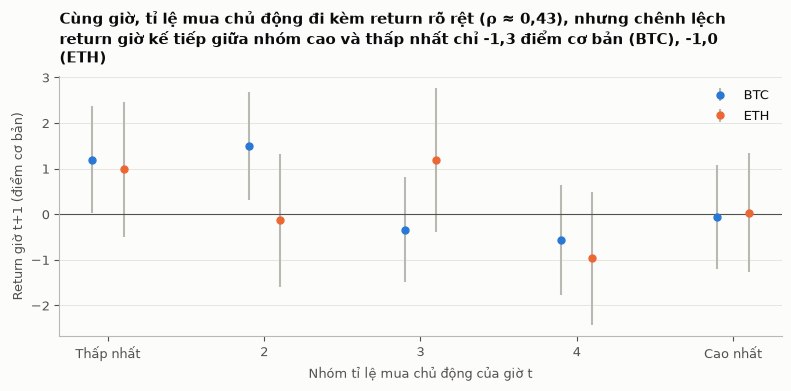

BTC: ρ giờ kế tiếp -0,037, giải thích 0,14% phương sai; có nhóm có khoảng tin cậy không chứa 0, nhưng độ lớn rất nhỏ
ETH: ρ giờ kế tiếp -0,032, giải thích 0,10% phương sai; mọi khoảng tin cậy của 5 nhóm đều chứa 0


In [19]:
fl = df[df["quote_volume"] > 0].copy()
fl["tbr"] = fl["taker_buy_quote"] / fl["quote_volume"]
fl = fl.sort_values(["symbol", "open_time"])
fl["next_ret"] = fl.groupby("symbol")["ret_1h"].shift(-1)
rows, qm, rho_next, spread, ci0 = [], {}, {}, {}, {}
for s in SYMS:
    g = fl[fl["symbol"] == s].dropna(subset=["tbr", "ret_1h", "next_ret"])
    r_now, r_next = stats.spearmanr(g["tbr"], g["ret_1h"])[0], stats.spearmanr(g["tbr"], g["next_ret"])[0]
    rows.append({"mã": NAME[s], "Spearman cùng giờ": vn(r_now, 2), "Spearman giờ kế tiếp": vn(r_next, 3), "số giờ": f"{len(g):,}".replace(",", ".")})
    g = g.assign(q=pd.qcut(g["tbr"], 5, labels=False))
    qm[s] = g.groupby("q")["next_ret"].agg(["mean", "sem"]) * 1e4
    rho_next[s] = r_next; spread[s] = qm[s]["mean"].iloc[-1] - qm[s]["mean"].iloc[0]
    ci0[s] = bool(((qm[s]["mean"] - 1.96 * qm[s]["sem"] <= 0) & (qm[s]["mean"] + 1.96 * qm[s]["sem"] >= 0)).all())
display(pd.DataFrame(rows).set_index("mã"))

fig, ax = plt.subplots(figsize=(8, 4))
for i, s in enumerate(SYMS):
    ax.errorbar(np.arange(5) + (i - 0.5) * 0.2, qm[s]["mean"], yerr=1.96 * qm[s]["sem"], fmt="o", ms=5, color=COL[s], ecolor=GREY, capsize=0, label=NAME[s])
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(range(5)); ax.set_xticklabels(["Thấp nhất", "2", "3", "4", "Cao nhất"]); ax.set_xlabel("Nhóm tỉ lệ mua chủ động của giờ t")
ax.set_ylabel("Return giờ t+1 (điểm cơ bản)")
ttl(ax, f"Cùng giờ, tỉ lệ mua chủ động đi kèm return rõ rệt (ρ ≈ {vn(np.mean([float(r['Spearman cùng giờ'].replace(',', '.')) for r in rows]), 2)}), "
        f"nhưng chênh lệch return giờ kế tiếp giữa nhóm cao và thấp nhất chỉ {vn(spread['BTCUSDT'], 1, sign=True)} điểm cơ bản (BTC), {vn(spread['ETHUSDT'], 1, sign=True)} (ETH)")
ax.legend(loc="upper right")
save(fig, "13_taker_du_bao")
for s in SYMS:
    print(f"{NAME[s]}: ρ giờ kế tiếp {vn(rho_next[s], 3)}, giải thích {vn(rho_next[s] ** 2, 2, pct=True)} phương sai; "
          f"{'mọi khoảng tin cậy của 5 nhóm đều chứa 0' if ci0[s] else 'có nhóm có khoảng tin cậy không chứa 0, nhưng độ lớn rất nhỏ'}")

## 9. Lý do của các đợt tăng giảm lớn

Câu hỏi 6. Phần lý do lấy từ tin tức và từ cách đọc thị trường của người phân tích, không suy ra từ dữ liệu giá. Cột "Căn cứ" cho biết lý do dựa vào nguồn nào: **Nguồn tin** là bài báo hoặc báo cáo xác nhận; **nhận định** là suy luận của người phân tích từ thời điểm và bối cảnh. Hai ô tính phía dưới kiểm tra dữ liệu giá có khớp với các mốc sự kiện hay không.

| Giai đoạn | BTC thay đổi | Sự kiện bên ngoài | Căn cứ |
| --- | --- | --- | --- |
| 08–12/2017, tăng | +346% | Nhà đầu tư nhỏ lẻ đổ vào cùng làn sóng ICO; 10 và 17/12/2017 CBOE, CME mở hợp đồng tương lai, đỉnh đúng 17/12 | Nguồn tin (Fed San Francisco) và nhận định |
| 12/2017–12/2018, giảm | −62%, rồi −72% | Bong bóng ICO vỡ, SEC xử lý các dự án ICO, hợp đồng tương lai cho phép đặt cược giá giảm | Nguồn tin (Investing.com) |
| 12/2018–12/2019 | +330%, rồi −51% | Đợt tăng: đầu 04/2019 giá vọt lên khoảng 5.000 USD trong thị trường mỏng, khoảng 500 triệu USD lệnh bán khống bị thanh lý trên BitMEX, phá đường trung bình 200 ngày, giá trị giao dịch gấp khoảng 5 lần đầu năm, làn sóng IEO thay cho ICO. Đợt giảm sau đỉnh giữa năm: chốt lời sau đợt tăng quá nhanh | Nguồn tin (The Block) và nhận định |
| 02–03/2020, giảm | −52% | Đại dịch COVID, bán mọi tài sản để giữ tiền mặt; 12/03/2020 BTC mất hơn 27% trong một ngày | Nguồn tin (BNN Bloomberg) |
| 03/2020–04/2021, tăng | +1.167% | Halving 05/2020 được kỳ vọng đẩy giá; gói kích thích tiền tệ và các tổ chức lớn mua Bitcoin làm dòng tiền vào mạnh | Nguồn tin (BNN Bloomberg) và nhận định |
| 04–07/2021, giảm | −53% | Tesla dừng nhận Bitcoin (12/05), Trung Quốc siết đào và giao dịch, Mỹ yêu cầu báo cáo giao dịch, lệnh đòn bẩy bị bán tự động | Nguồn tin (Coinbase) |
| 07–11/2021, tăng | +131% đến 10/11/2021 | 19/10/2021 quỹ ETF đầu tiên ở Mỹ đầu tư vào hợp đồng tương lai Bitcoin (ProShares BITO) lên sàn, huy động 570 triệu USD và giao dịch 1 tỷ USD ngay ngày đầu; BTC vượt 66.000 USD, qua đỉnh cũ của tháng 4 | Nguồn tin (CoinDesk) |
| 11/2021–11/2022, giảm | −77% | Fed tăng lãi suất, TerraUSD mất neo (05/2022), 3AC và Celsius sụp đổ, FTX phá sản (11/2022) | Nguồn tin (The Block) |
| 11/2022–10/2025, tăng | +683% | 2023: hồi từ đáy sau FTX khoảng 16.000 lên 24.800 trong quý 1, khủng hoảng ngân hàng SVB và Silvergate tháng 3 đẩy giá về khoảng 20.000 rồi hồi nhanh, BlackRock nộp hồ sơ ETF giao ngay tháng 6, vượt 40.000 tháng 10. 2024: ETF giao ngay giao dịch từ 11/01, halving 04/2024, vượt đỉnh cũ 05/03/2024. Sau bầu cử Mỹ 11/2024 vượt 100.000 nhờ kỳ vọng chính sách ủng hộ crypto | Nguồn tin (CoinMarketCap Academy, Investing.com) và nhận định |
| 10/2025–02/2026, giảm | từ khoảng 124.700 xuống khoảng 63.000 | 10/10/2025 hơn 19 tỷ USD lệnh đòn bẩy bị thanh lý trong 24 giờ; ETF bị rút ròng khoảng 7, 2 và 3 tỷ USD (11/2025–01/2026) | Nguồn tin (Decrypt, Al Jazeera) |
| 02–06/2026, giảm tiếp | xuống 58.625 | ETF rút ròng kỷ lục khoảng 4,5 tỷ USD trong tháng 6, Strategy lần đầu bán BTC | Nguồn tin (Bitcoin.com, IG) |
| 07–09/2026, hồi phục | +25% riêng tháng 8 | Bộ Tài chính Mỹ mua lại trái phiếu, đề xuất của SEC, khoảng 1,4 tỷ USD lệnh bán khống bị thanh lý, ETF hút vào 3,05 tỷ USD | Nguồn tin (21Shares) |
| 29–30/10/2026 | −4,5% trong khoảng 6 giờ | Binance báo mất khoảng 6,3 tỷ USD trong vụ tấn công, tạm dừng nạp rút | Nguồn tin (Reuters, RTTNews) |

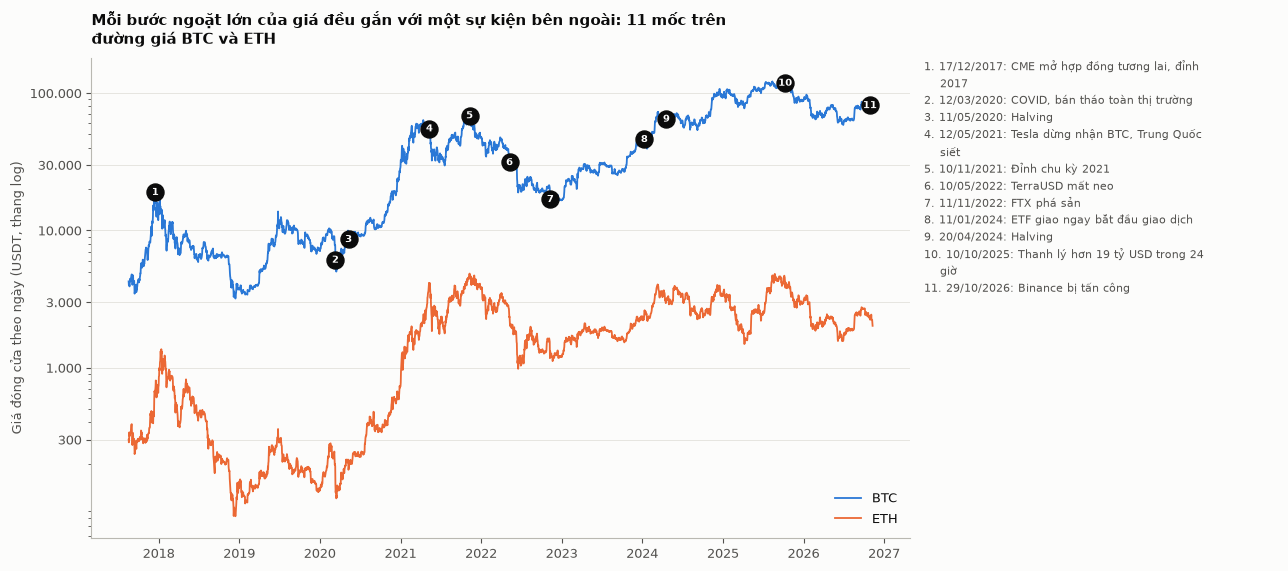

In [20]:
# Biểu đồ: các mốc sự kiện trên đường giá (thang log, ngày theo giờ Việt Nam)
MARKS = [
    (1, "2017-12-17", "CME mở hợp đồng tương lai, đỉnh 2017"),
    (2, "2020-03-12", "COVID, bán tháo toàn thị trường"),
    (3, "2020-05-11", "Halving"),
    (4, "2021-05-12", "Tesla dừng nhận BTC, Trung Quốc siết"),
    (5, "2021-11-10", "Đỉnh chu kỳ 2021"),
    (6, "2022-05-10", "TerraUSD mất neo"),
    (7, "2022-11-11", "FTX phá sản"),
    (8, "2024-01-11", "ETF giao ngay bắt đầu giao dịch"),
    (9, "2024-04-20", "Halving"),
    (10, "2025-10-10", "Thanh lý hơn 19 tỷ USD trong 24 giờ"),
    (11, "2026-10-29", "Binance bị tấn công"),
]
fig, (ax, axt) = plt.subplots(1, 2, figsize=(13, 5.8), gridspec_kw={"width_ratios": [3, 1.3]})
axt.axis("off")
for s in SYMS:
    ax.plot(px.index, px[s], color=COL[s], lw=1.3, label=NAME[s])
ax.set_yscale("log")
ax.yaxis.set_major_formatter(fmt_int)
ax.set_yticks([300, 1000, 3000, 10000, 30000, 100000])
for n, dt, _ in MARKS:
    t = pd.Timestamp(dt); y = px.loc[px.index[px.index.get_indexer([t], method="nearest")[0]], "BTCUSDT"]
    ax.scatter([t], [y], s=150, color=INK, zorder=5)
    ax.text(t, y, str(n), ha="center", va="center", color="white", fontsize=7.5, fontweight="bold", zorder=6)
axt.text(0, 1.0, "\n".join(f"{n}. {dmy(dt)}: " + textwrap.fill(lab, 32).replace("\n", "\n    ") for n, dt, lab in MARKS), transform=axt.transAxes, va="top", fontsize=8.2, color=INK2, linespacing=1.5)
ax.legend(loc="lower right")
ttl(ax, f"Mỗi bước ngoặt lớn của giá đều gắn với một sự kiện bên ngoài: {len(MARKS)} mốc trên đường giá BTC và ETH")
ax.set_ylabel("Giá đóng cửa theo ngày (USDT, thang log)")
save(fig, "13b_moc_su_kien")

In [21]:
# Đối chiếu dữ liệu giá với các mốc có ngày cụ thể (ngày theo giờ Việt Nam, giống các mục trên)
EVENTS = [("COVID, 12/03/2020", "2020-03-12"), ("COVID, 13/03/2020", "2020-03-13"), ("Thanh lý, sáng 11/10/2025", "2025-10-11"), ("Binance bị tấn công, 30/10/2026", "2026-10-30")]
qv = daily.pivot(index="day", columns="symbol", values="qv")[SYMS]
rel = qv / qv.rolling(30).median().shift(1)
dret = px.pct_change()
rows = []
for label, dt in EVENTS:
    for s in SYMS:
        rows.append([label, NAME[s], vn(dret.loc[dt, s], 1, pct=True), f"{vn(rel.loc[dt, s], 1)} lần"])
display(pd.DataFrame(rows, columns=["Sự kiện", "Mã", "Thay đổi trong ngày", "Khối lượng so với trung vị 30 ngày"]))
print("Lưu ý: ngày tính theo giờ Việt Nam nên một cú sập kéo qua nửa đêm bị chia làm hai ngày (COVID: -21,6% rồi -14,6%). Cú sập 12/03/2020 theo BNN Bloomberg là hơn 27% trong một ngày; cả hai cách đều cho thấy đây là chuỗi ngày giảm kỷ lục. Vụ thanh lý 10/10/2025 xảy ra khoảng 4h sáng 11/10 giờ Việt Nam.")

,Sự kiện,Mã,Thay đổi trong ngày,Khối lượng so với trung vị 30 ngày
0,"COVID, 12/03/2020",BTC,"-21,6%","2,6 lần"
1,"COVID, 12/03/2020",ETH,"-27,4%","2,7 lần"
2,"COVID, 13/03/2020",BTC,"-14,6%","3,9 lần"
3,"COVID, 13/03/2020",ETH,"-11,4%","3,1 lần"
4,"Thanh lý, sáng 11/10/2025",BTC,"-5,4%","5,3 lần"
5,"Thanh lý, sáng 11/10/2025",ETH,"-7,0%","3,4 lần"
6,"Binance bị tấn công, 30/10/2026",BTC,"-4,8%","2,3 lần"
7,"Binance bị tấn công, 30/10/2026",ETH,"-5,1%","2,5 lần"


Lưu ý: ngày tính theo giờ Việt Nam nên một cú sập kéo qua nửa đêm bị chia làm hai ngày (COVID: -21,6% rồi -14,6%). Cú sập 12/03/2020 theo BNN Bloomberg là hơn 27% trong một ngày; cả hai cách đều cho thấy đây là chuỗi ngày giảm kỷ lục. Vụ thanh lý 10/10/2025 xảy ra khoảng 4h sáng 11/10 giờ Việt Nam.


In [22]:
# Vụ Binance theo từng nến giờ: 02h đến 08h giờ Việt Nam sáng 30/10/2026 (19h UTC 29/10 đến 01h UTC 30/10)
for s in SYMS:
    w = df[(df["symbol"] == s) & (df["open_time"] >= "2026-10-29 19:00:00+00:00") & (df["open_time"] <= "2026-10-30 00:00:00+00:00")]
    chg = w["close"].iloc[-1] / w["open"].iloc[0] - 1
    worst = (w["close"] / w["open"] - 1).idxmin()
    print(f"{NAME[s]}: {vn(w['open'].iloc[0], 0)} → {vn(w['close'].iloc[-1], 0)} ({vn(chg, 1, pct=True)}); nến giảm mạnh nhất lúc {w.loc[worst, 't']:%H}h giờ Việt Nam: {vn(w.loc[worst, 'close'] / w.loc[worst, 'open'] - 1, 1, pct=True)}")

BTC: 80.864 → 77.252 (-4,5%); nến giảm mạnh nhất lúc 03h giờ Việt Nam: -2,5%
ETH: 2.331 → 2.223 (-4,7%); nến giảm mạnh nhất lúc 03h giờ Việt Nam: -3,4%


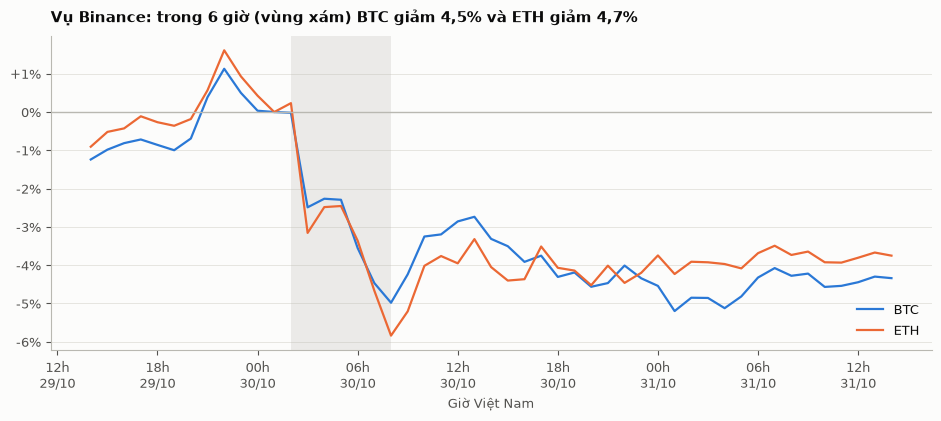

In [23]:
# Biểu đồ: vụ Binance theo từng giờ (số chỉ phần trăm thay đổi so với giá lúc 02h sáng 30/10 giờ Việt Nam)
T0 = pd.Timestamp("2026-10-29 19:00:00+00:00")
fig, ax = plt.subplots(figsize=(9.5, 4.3))
res = {}
for s in SYMS:
    g = df[(df["symbol"] == s) & (df["open_time"] >= T0 - pd.Timedelta(hours=12)) & (df["open_time"] <= T0 + pd.Timedelta(hours=36))]
    base = g.loc[g["open_time"] == T0, "open"].iloc[0]
    ax.plot(g["t"], (g["close"] / base - 1) * 100, color=COL[s], lw=1.6, label=NAME[s])
    w = g[(g["open_time"] >= T0) & (g["open_time"] <= T0 + pd.Timedelta(hours=5))]
    res[s] = w["close"].iloc[-1] / base - 1
ax.axvspan(T0.tz_convert(TZ), (T0 + pd.Timedelta(hours=6)).tz_convert(TZ), color=GREY, alpha=0.25, lw=0)
ax.axhline(0, color=GREY, lw=1)
ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v:+.0f}%".replace("+0%", "0%")))
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 6), tz=TZ))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Hh\n%d/%m", tz=TZ))
ax.set_xlabel("Giờ Việt Nam")
ax.legend(loc="lower right")
ttl(ax, f"Vụ Binance: trong 6 giờ (vùng xám) BTC giảm {vn(-res['BTCUSDT'], 1, pct=True)} và ETH giảm {vn(-res['ETHUSDT'], 1, pct=True)}")
save(fig, "13c_binance")

## 10. Giữ bao lâu, phí và đòn bẩy

Câu hỏi 7. Dùng cùng dữ liệu đã làm sạch: bỏ nến cuối chưa đóng, ngày tính theo giờ Việt Nam, bỏ ngày đầu và ngày cuối chưa đủ 24 giờ (`px`). Các lần mua chồng lấn nhau, nên đây là tần suất lịch sử, không phải xác suất độc lập.

### 10.1 Nhìn dài hạn: từ 2017 đến nay

In [24]:
rows = []
for s in SYMS:
    p = px[s]
    rows.append([NAME[s], dmy(p.index[0]), vn(p.iloc[0], 0), dmy(p.index[-1]), vn(p.iloc[-1], 0), times(p.iloc[-1] / p.iloc[0])])
display(pd.DataFrame(rows, columns=["Mã", "Ngày đầu", "Giá đầu", "Ngày cuối", "Giá cuối", "Mức tăng"]))

,Mã,Ngày đầu,Giá đầu,Ngày cuối,Giá cuối,Mức tăng
0,BTC,18/08/2017,4.250,10/11/2026,72.881,"gấp 17,1 lần"
1,ETH,18/08/2017,299,10/11/2026,2.018,"gấp 6,7 lần"


### 10.2 Xác suất có lãi theo thời gian giữ (nến giờ)

Mỗi giờ là một lần mua, bán sau 1 giờ, 1 ngày, 30 ngày, 1 năm.

In [25]:
hp = df.pivot(index="open_time", columns="symbol", values="close")[SYMS]
rows = []
for name, n in [("1 giờ", 1), ("1 ngày", 24), ("30 ngày", 24 * 30), ("1 năm", 24 * 365)]:
    r = (hp.shift(-n) / hp - 1)
    rows.append([name] + [(r[s].dropna() > 0).mean() for s in SYMS])
win_h = pd.DataFrame(rows, columns=["Thời gian giữ", "BTC", "ETH"])
display(win_h.assign(BTC=win_h["BTC"].map(lambda v: vn(v, 1, pct=True)), ETH=win_h["ETH"].map(lambda v: vn(v, 1, pct=True))).rename(columns={"BTC": "BTC có lãi", "ETH": "ETH có lãi"}))

,Thời gian giữ,BTC có lãi,ETH có lãi
0,1 giờ,"50,8%","50,5%"
1,1 ngày,"52,0%","51,5%"
2,30 ngày,"54,6%","52,2%"
3,1 năm,"63,6%","52,8%"


### 10.3 Giữ nhiều năm (nến ngày)

Lãi/lỗ là phần trăm thay đổi giá sau N năm. Cột "tệ nhất" là lần mua gặp kết quả xấu nhất.

In [26]:
rows = []
for y in [1, 2, 3, 4]:
    for s in SYMS:
        r = (px[s].shift(-365 * y) / px[s] - 1).dropna()
        rows.append([f"{y} năm", NAME[s], len(r), (r > 0).mean(), r.median(), r.min()])
hold = pd.DataFrame(rows, columns=["Giữ", "Mã", "Số lần mua", "Tỉ lệ có lãi", "Trung vị", "Tệ nhất"])
display(hold.assign(**{c: hold[c].map(lambda v: vn(v, 0, pct=True)) for c in ["Tỉ lệ có lãi", "Trung vị", "Tệ nhất"]}))

,Giữ,Mã,Số lần mua,Tỉ lệ có lãi,Trung vị,Tệ nhất
0,1 năm,BTC,3007,64%,38%,-83%
1,1 năm,ETH,3007,53%,7%,-92%
2,2 năm,BTC,2642,76%,101%,-65%
3,2 năm,ETH,2642,62%,42%,-89%
4,3 năm,BTC,2277,100%,162%,-11%
5,3 năm,ETH,2277,86%,150%,-54%
6,4 năm,BTC,1912,100%,259%,30%
7,4 năm,ETH,1912,87%,497%,-52%


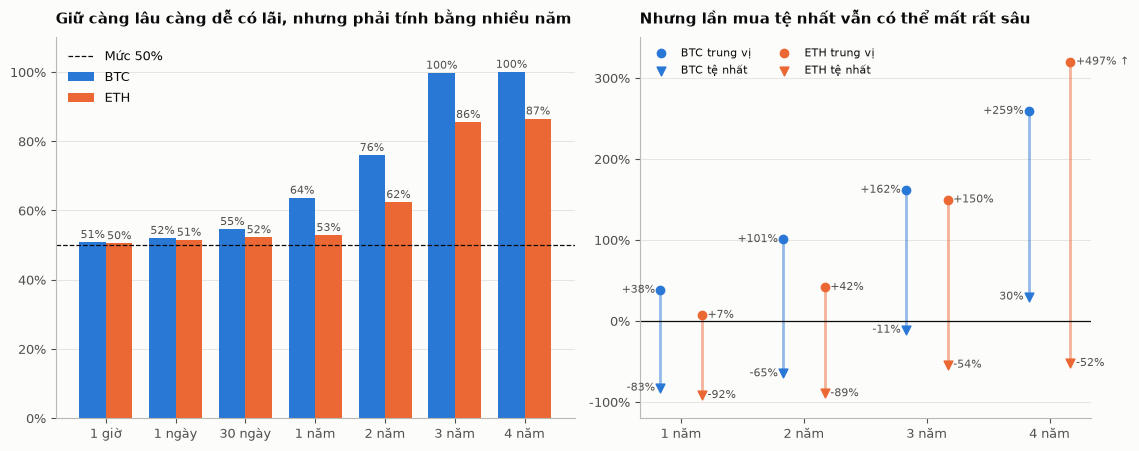

In [27]:
# Biểu đồ: giữ bao lâu thì có lãi, và kết quả tệ nhất
dur = ["1 giờ", "1 ngày", "30 ngày", "1 năm"]
yrs = ["2 năm", "3 năm", "4 năm"]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
labels = dur + yrs
x = np.arange(len(labels)); w = 0.38
for k, s in enumerate(SYMS):
    v = list(win_h.set_index("Thời gian giữ")[NAME[s]].reindex(dur)) + [hold[(hold["Giữ"] == y) & (hold["Mã"] == NAME[s])]["Tỉ lệ có lãi"].iloc[0] for y in yrs]
    b = ax.bar(x + (k - 0.5) * w, v, w, color=COL[s], label=NAME[s])
    for xi, vi in zip(x + (k - 0.5) * w, v):
        ax.text(xi, vi + 0.012, vn(vi, 0, pct=True), ha="center", fontsize=7.8, color=INK2)
ax.axhline(0.5, color=INK, lw=0.9, ls="--", label="Mức 50%")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0, 1.1); ax.yaxis.set_major_formatter(fmt_pct0)
ax.legend(loc="upper left")
ttl(ax, "Giữ càng lâu càng dễ có lãi, nhưng phải tính bằng nhiều năm")
ax = axes[1]
yy = ["1 năm", "2 năm", "3 năm", "4 năm"]
x = np.arange(len(yy)); CAP = 3.2
for k, s in enumerate(SYMS):
    d = hold[hold["Mã"] == NAME[s]].set_index("Giữ").reindex(yy)
    xs = x + (k - 0.5) * 0.34
    med = d["Trung vị"].clip(upper=CAP)
    ax.vlines(xs, d["Tệ nhất"], med, color=COL[s], lw=2, alpha=0.5)
    ax.scatter(xs, med, color=COL[s], s=36, zorder=3, label=f"{NAME[s]} trung vị")
    ax.scatter(xs, d["Tệ nhất"], color=COL[s], marker="v", s=40, zorder=3, label=f"{NAME[s]} tệ nhất")
    side, ha = (-0.045, "right") if k == 0 else (0.045, "left")
    for xi, vi, vm in zip(xs, d["Tệ nhất"], d["Trung vị"]):
        ax.text(xi + side, vi, vn(vi, 0, pct=True), ha=ha, va="center", fontsize=8, color=INK2)
        ax.text(xi + side, min(vm, CAP), vn(vm, 0, pct=True, sign=True) + (" ↑" if vm > CAP else ""), ha=ha, va="center", fontsize=8, color=INK2)
ax.axhline(0, color=INK, lw=0.9)
ax.set_xticks(x); ax.set_xticklabels(yy); ax.set_ylim(-1.2, 3.5); ax.yaxis.set_major_formatter(fmt_pct0)
ax.legend(loc="upper left", fontsize=8, ncol=2)
ttl(ax, "Nhưng lần mua tệ nhất vẫn có thể mất rất sâu")
save(fig, "13d_giu_bao_lau")

Giữ càng lâu thì tỉ lệ có lãi càng cao, nhưng "lâu" ở đây là nhiều năm: giữ 1 năm vẫn có lần mất khoảng 83% (BTC) và 92% (ETH). Mẫu chỉ có 9 năm, các lần mua chồng lấn, dữ liệu bắt đầu từ vùng giá thấp 2017 và chỉ có hai đồng còn tồn tại đến nay, nên đây là điều đã xảy ra, không phải bảo đảm.

### 10.4 Điểm vào: mua đúng đỉnh thì sao

Đỉnh được xác định trên BTC (giá đóng cửa ngày cao nhất trong tháng đó); ETH mua cùng ngày.

In [28]:
rows = []
for label, a, b in [("Đỉnh chu kỳ trước", "2021-11-01", "2021-11-30"), ("Đỉnh gần nhất", "2025-10-01", "2025-10-31")]:
    dt = px["BTCUSDT"].loc[a:b].idxmax()
    for s in SYMS:
        rows.append([f"{label} ({dmy(dt)})", NAME[s], px.loc[dt, s], px[s].iloc[-1], px[s].iloc[-1] / px.loc[dt, s] - 1])
peak = pd.DataFrame(rows, columns=["Mua vào", "Mã", "Giá mua", f"Giá {dmy(px.index[-1])}", "Lãi/lỗ đến nay"])
display(peak.assign(**{"Giá mua": peak["Giá mua"].map(lambda v: vn(v, 0)), peak.columns[3]: peak[peak.columns[3]].map(lambda v: vn(v, 0)),
                       "Lãi/lỗ đến nay": peak["Lãi/lỗ đến nay"].map(lambda v: vn(v, 1, pct=True, sign=True))}))

,Mua vào,Mã,Giá mua,Giá 10/11/2026,Lãi/lỗ đến nay
0,Đỉnh chu kỳ trước (10/11/2021),BTC,68.525,72.881,"+6,4%"
1,Đỉnh chu kỳ trước (10/11/2021),ETH,4.846,2.018,"-58,3%"
2,Đỉnh gần nhất (06/10/2025),BTC,125.455,72.881,"-41,9%"
3,Đỉnh gần nhất (06/10/2025),ETH,4.678,2.018,"-56,9%"


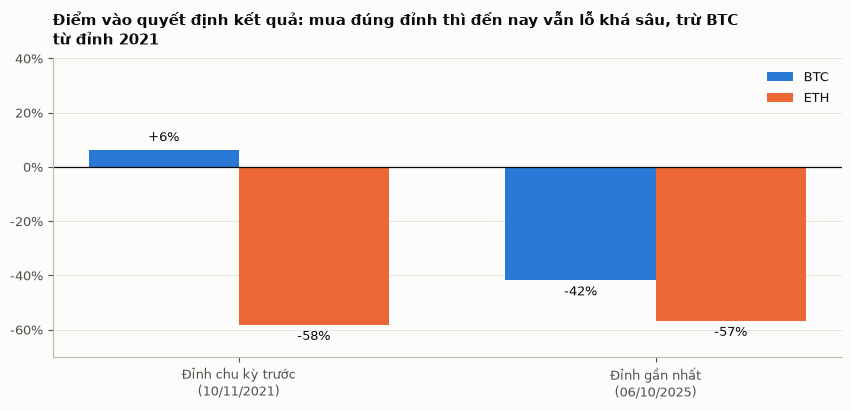

In [29]:
# Biểu đồ: mua đúng đỉnh thì đến nay lãi hay lỗ
fig, ax = plt.subplots(figsize=(8.6, 4.2))
groups = list(dict.fromkeys(peak["Mua vào"]))
x = np.arange(len(groups)); w = 0.36
for k, s in enumerate(SYMS):
    v = [peak[(peak["Mua vào"] == g) & (peak["Mã"] == NAME[s])]["Lãi/lỗ đến nay"].iloc[0] for g in groups]
    ax.bar(x + (k - 0.5) * w, v, w, color=COL[s], label=NAME[s])
    for xi, vi in zip(x + (k - 0.5) * w, v):
        ax.text(xi, vi + (0.02 if vi >= 0 else -0.02), vn(vi, 0, pct=True, sign=True), ha="center", va="bottom" if vi >= 0 else "top", fontsize=9, color=INK)
ax.axhline(0, color=INK, lw=0.9)
ax.set_xticks(x); ax.set_xticklabels([textwrap.fill(g, 24) for g in groups]); ax.yaxis.set_major_formatter(fmt_pct0)
ax.set_ylim(-0.7, 0.4); ax.legend(loc="upper right")
ttl(ax, "Điểm vào quyết định kết quả: mua đúng đỉnh thì đến nay vẫn lỗ khá sâu, trừ BTC từ đỉnh 2021")
save(fig, "13e_mua_dung_dinh")

### 10.5 Phí so với biên độ giá

Giả định phí 0,1% mỗi chiều (mức phí cơ bản của Binance, chưa tính ưu đãi), tức khoảng 0,2% cho một lượt mua và bán. Đổi `FEE_ONE_WAY` nếu mức phí của bạn khác.

In [30]:
FEE_ONE_WAY = 0.001
fee = 2 * FEE_ONE_WAY
rows = []
for s in SYMS:
    h1 = df[df["symbol"] == s]["ret_1h"].abs().median()
    h1 = np.exp(h1) - 1
    d1 = px[s].pct_change().abs().median()
    d30 = (px[s].shift(-30) / px[s] - 1).abs().median()
    for name, mv in [("1 giờ", h1), ("1 ngày", d1), ("30 ngày", d30)]:
        rows.append([NAME[s], name, mv, fee / mv])
feetab = pd.DataFrame(rows, columns=["Mã", "Thời gian giữ", "Biên độ trung vị", "Phí chiếm bao nhiêu biên độ"])
display(feetab.assign(**{"Biên độ trung vị": feetab["Biên độ trung vị"].map(lambda v: vn(v, 2, pct=True)), "Phí chiếm bao nhiêu biên độ": feetab["Phí chiếm bao nhiêu biên độ"].map(lambda v: vn(v, 0, pct=True))}))

,Mã,Thời gian giữ,Biên độ trung vị,Phí chiếm bao nhiêu biên độ
0,BTC,1 giờ,"0,25%",80%
1,BTC,1 ngày,"1,47%",14%
2,BTC,30 ngày,"11,43%",2%
3,ETH,1 giờ,"0,34%",59%
4,ETH,1 ngày,"2,02%",10%
5,ETH,30 ngày,"15,62%",1%


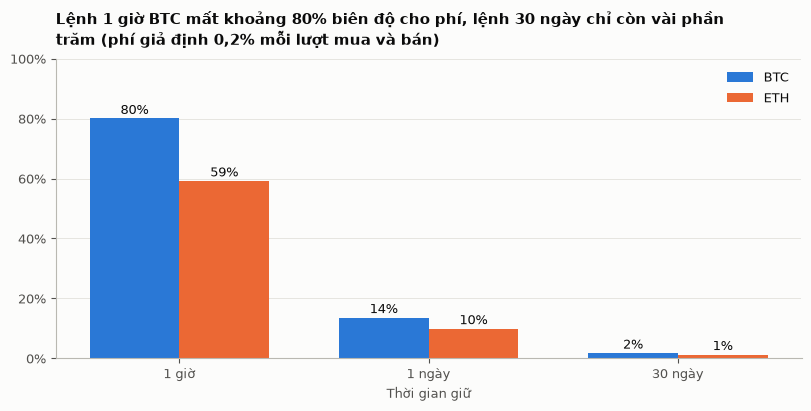

In [31]:
# Biểu đồ: phí ăn bao nhiêu phần biên độ giá
fig, ax = plt.subplots(figsize=(8.2, 4.2))
names = ["1 giờ", "1 ngày", "30 ngày"]
x = np.arange(len(names)); w = 0.36
for k, s in enumerate(SYMS):
    v = [feetab[(feetab["Mã"] == NAME[s]) & (feetab["Thời gian giữ"] == n)]["Phí chiếm bao nhiêu biên độ"].iloc[0] for n in names]
    ax.bar(x + (k - 0.5) * w, v, w, color=COL[s], label=NAME[s])
    for xi, vi in zip(x + (k - 0.5) * w, v):
        ax.text(xi, vi + 0.015, vn(vi, 0, pct=True), ha="center", fontsize=9, color=INK)
ax.set_xticks(x); ax.set_xticklabels(names); ax.yaxis.set_major_formatter(fmt_pct0); ax.set_ylim(0, 1)
ax.set_xlabel("Thời gian giữ"); ax.legend(loc="upper right")
b1 = feetab[(feetab["Mã"] == "BTC") & (feetab["Thời gian giữ"] == "1 giờ")]["Phí chiếm bao nhiêu biên độ"].iloc[0]
ttl(ax, f"Lệnh 1 giờ BTC mất khoảng {vn(b1, 0, pct=True)} biên độ cho phí, lệnh 30 ngày chỉ còn vài phần trăm (phí giả định {vn(fee, 1, pct=True)} mỗi lượt mua và bán)")
save(fig, "13f_phi_giao_dich")

### 10.6 Đòn bẩy: ngưỡng thanh lý nằm ở đâu so với một ngày xấu

Với đòn bẩy L, vị thế bị thanh lý khi giá đi ngược khoảng 1/L (chưa tính ký quỹ duy trì, nên thực tế còn gần hơn). Ngày tính theo giờ Việt Nam nên cú sập kéo qua nửa đêm bị chia làm hai ngày; cột "24 giờ liền tệ nhất" đo trọn vẹn một cú sập.

In [32]:
rows = []
for s in SYMS:
    r1 = px[s].pct_change().dropna()
    r24 = (hp[s].shift(-24) / hp[s] - 1).dropna()
    rows.append([NAME[s], r1.quantile(0.05), r1.min(), r24.min(), (r1 <= -0.10).mean()])
lev = pd.DataFrame(rows, columns=["Mã", "Ngày tệ hơn mức này (cứ 20 ngày có 1)", "Ngày tệ nhất", "24 giờ liền tệ nhất", "Số ngày giảm từ 10% trở lên"])
print("Đòn bẩy 10 lần bị thanh lý khi giá đi ngược khoảng", vn(1 / 10, 0, pct=True))
display(lev.assign(**{c: lev[c].map(lambda v: vn(v, 2 if c.startswith("Số ngày") else 1, pct=True)) for c in lev.columns[1:]}))

Đòn bẩy 10 lần bị thanh lý khi giá đi ngược khoảng 10%


,Mã,Ngày tệ hơn mức này (cứ 20 ngày có 1),Ngày tệ nhất,24 giờ liền tệ nhất,Số ngày giảm từ 10% trở lên
0,BTC,"-5,0%","-21,6%","-46,4%","0,89%"
1,ETH,"-6,6%","-27,4%","-47,8%","1,96%"


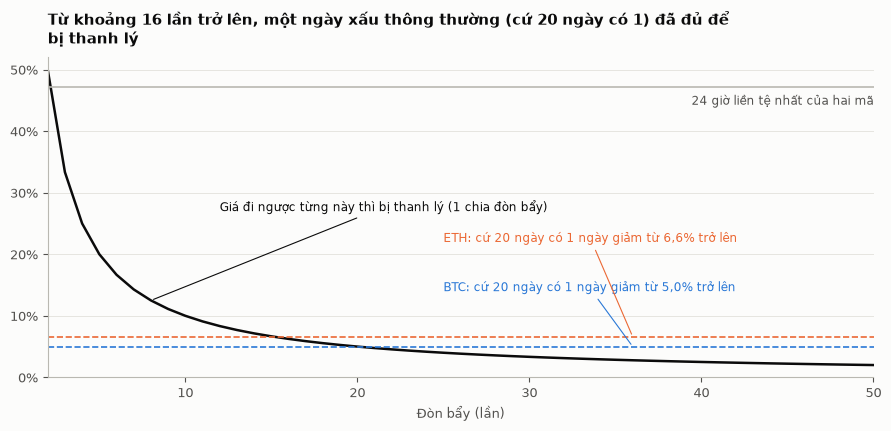

In [33]:
# Biểu đồ: đòn bẩy bao nhiêu thì một ngày xấu thông thường đã đủ thanh lý
L = np.arange(2, 51)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(L, 100 / L, color=INK, lw=1.8)
ax.annotate("Giá đi ngược từng này thì bị thanh lý (1 chia đòn bẩy)", xy=(8, 12.5), xytext=(12, 27), fontsize=8.5, color=INK, arrowprops=dict(arrowstyle="-", color=INK, lw=0.8))
p5 = {s: -lev[lev["Mã"] == NAME[s]]["Ngày tệ hơn mức này (cứ 20 ngày có 1)"].iloc[0] * 100 for s in SYMS}
for s, ty in zip(SYMS, [17, 22]):
    ax.axhline(p5[s], color=COL[s], lw=1.2, ls="--")
    ax.annotate(f"{NAME[s]}: cứ 20 ngày có 1 ngày giảm từ {vn(p5[s], 1)}% trở lên", xy=(36, p5[s]), xytext=(25, ty if s == "ETHUSDT" else 14),
                fontsize=8.5, color=COL[s], arrowprops=dict(arrowstyle="-", color=COL[s], lw=0.8))
w24 = -lev["24 giờ liền tệ nhất"].mean() * 100
ax.axhline(w24, color=GREY, lw=1.2)
ax.text(50, w24 - 1.2, "24 giờ liền tệ nhất của hai mã", color=INK2, fontsize=8.5, ha="right", va="top")
ax.set_xlim(2, 50); ax.set_ylim(0, 52)
ax.set_xlabel("Đòn bẩy (lần)"); ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
lmin = int(np.ceil(100 / max(p5.values())))
ttl(ax, f"Từ khoảng {lmin} lần trở lên, một ngày xấu thông thường (cứ 20 ngày có 1) đã đủ để bị thanh lý")
save(fig, "13g_don_bay")

### 10.7 Sau một đợt tăng mạnh

Lấy các ngày mà 30 ngày trước giá đã tăng từ 50% trở lên, xem 30 ngày kế tiếp. Các ngày liền nhau chồng lấn, nên số lần thực chất ít hơn số ngày.

In [34]:
rows = []
for s in SYMS:
    d = px[s]
    past = d / d.shift(30) - 1
    fut = d.shift(-30) / d - 1
    low30 = pd.concat([d.shift(-k) for k in range(1, 31)], axis=1).min(axis=1) / d - 1
    ok = fut.notna()
    m = (past >= 0.5) & ok
    rows.append([NAME[s], int(m.sum()), d.index[m].year.nunique(), fut[m].median(), (fut[m] < 0).mean(), (fut[ok] < 0).mean(),
                 (low30[m] <= -0.2).mean(), (low30[ok] <= -0.2).mean()])
rally = pd.DataFrame(rows, columns=["Mã", "Số ngày", "Số năm có", "30 ngày sau: trung vị", "Tỉ lệ giảm (sau đợt tăng)", "Tỉ lệ giảm (bình thường)",
                                    "Có lúc thấp hơn 20% (sau đợt tăng)", "Có lúc thấp hơn 20% (bình thường)"])
display(rally.assign(**{c: rally[c].map(lambda v: vn(v, 1 if c.startswith("30") else 0, pct=True)) for c in rally.columns[3:]}))

,Mã,Số ngày,Số năm có,30 ngày sau: trung vị,Tỉ lệ giảm (sau đợt tăng),Tỉ lệ giảm (bình thường),Có lúc thấp hơn 20% (sau đợt tăng),Có lúc thấp hơn 20% (bình thường)
0,BTC,115,5,"13,7%",28%,45%,24%,15%
1,ETH,262,8,"-1,8%",53%,48%,33%,24%


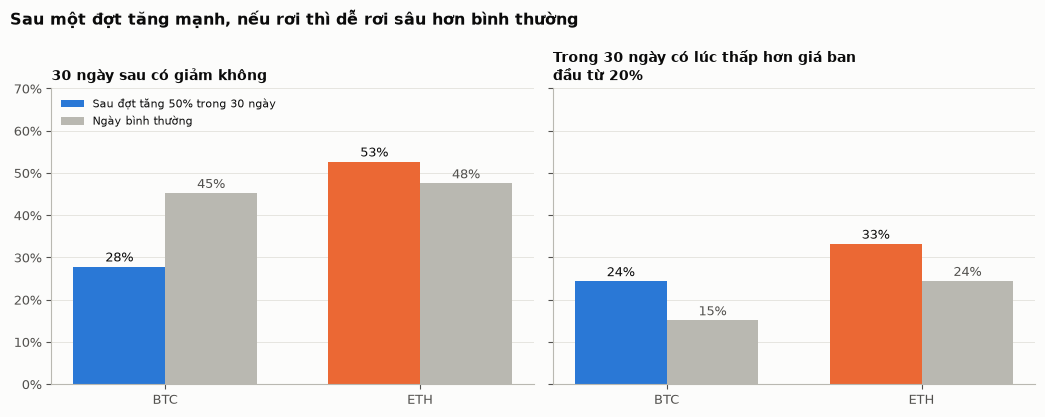

In [35]:
# Biểu đồ: sau một đợt tăng mạnh so với ngày bình thường
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
panels = [("Tỉ lệ giảm", "Tỉ lệ giảm (sau đợt tăng)", "Tỉ lệ giảm (bình thường)", "30 ngày sau có giảm không"),
          ("Thấp hơn 20%", "Có lúc thấp hơn 20% (sau đợt tăng)", "Có lúc thấp hơn 20% (bình thường)", "Trong 30 ngày có lúc thấp hơn giá ban đầu từ 20%")]
for ax, (_, c1, c2, sub) in zip(axes, panels):
    x = np.arange(2); w = 0.36
    a = rally[c1].values; b = rally[c2].values
    ax.bar(x - w / 2, a, w, color=[COL[s] for s in SYMS], label="Sau đợt tăng 50% trong 30 ngày")
    ax.bar(x + w / 2, b, w, color=GREY, label="Ngày bình thường")
    for xi, vi in zip(x - w / 2, a): ax.text(xi, vi + 0.012, vn(vi, 0, pct=True), ha="center", fontsize=9, color=INK)
    for xi, vi in zip(x + w / 2, b): ax.text(xi, vi + 0.012, vn(vi, 0, pct=True), ha="center", fontsize=9, color=INK2)
    ax.set_xticks(x); ax.set_xticklabels(["BTC", "ETH"]); ax.yaxis.set_major_formatter(fmt_pct0); ax.set_ylim(0, 0.7)
    ax.set_title(textwrap.fill(sub, 40), loc="left", fontsize=10, fontweight="bold", color=INK)
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Sau một đợt tăng mạnh, nếu rơi thì dễ rơi sâu hơn bình thường", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
save(fig, "13h_sau_dot_tang")

BTC sau đợt tăng mạnh vẫn thường tăng tiếp, nhưng nếu rơi thì dễ rơi sâu hơn bình thường. ETH yếu hơn: khoảng một nửa số lần giảm. Mẫu nhỏ và chồng lấn, nên đây là mô tả, không dùng để dự báo.

## 11. Bất thường

Phần này trả lời hai câu hỏi: ngoại lai (IQR × 3 trên return giờ, ngưỡng tính trên toàn bộ phạm vi) tập trung ở năm nào, và những ngày biến động mạnh nhất rơi vào đâu. Nguyên nhân của từng ngày cần đối chiếu với nguồn tin bên ngoài, notebook chỉ định vị thời điểm.

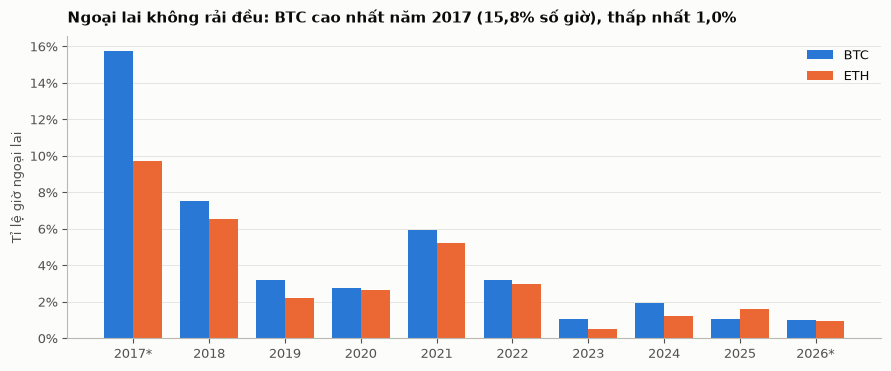

BTC - 8 ngày có |log-return ngày| lớn nhất


,ngày,log-return ngày
0,12/03/2020,"-24,3%"
1,27/06/2019,"-21,3%"
2,11/01/2021,"-21,1%"
3,30/12/2017,"-20,6%"
4,22/12/2017,"-19,3%"
5,16/01/2018,"-19,2%"
6,26/06/2019,"+18,6%"
7,09/11/2022,"-17,6%"


Trong 30 ngày lớn nhất của BTC: theo năm {2017: 10, 2018: 4, 2019: 3, 2020: 5, 2021: 5, 2022: 2, 2023: 1}
ETH - 8 ngày có |log-return ngày| lớn nhất


,ngày,log-return ngày
0,12/03/2020,"-32,1%"
1,11/01/2021,"-29,7%"
2,24/05/2021,"+28,9%"
3,09/11/2022,"-27,5%"
4,12/12/2017,"+24,7%"
5,23/05/2021,"-24,1%"
6,22/12/2017,"-23,0%"
7,13/09/2018,"+19,9%"


Trong 30 ngày lớn nhất của ETH: theo năm {2017: 6, 2018: 10, 2019: 2, 2020: 4, 2021: 5, 2022: 2, 2024: 1}


In [36]:
oy = df.dropna(subset=["ret_1h"]).groupby([df["t"].dt.year, "symbol"])["out3"].mean().unstack()[SYMS]
oy.index.name = "year"
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(oy)); w = 0.38
for i, s in enumerate(SYMS):
    ax.bar(x + (i - 0.5) * w, oy[s].values, w, color=COL[s], label=NAME[s])
ax.set_xticks(x); ax.set_xticklabels([ylab(y) for y in oy.index]); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: vn(v, 0, pct=True)))
ax.set_ylabel("Tỉ lệ giờ ngoại lai")
top_year = oy["BTCUSDT"].idxmax()
ttl(ax, f"Ngoại lai không rải đều: BTC cao nhất năm {top_year} ({vn(oy['BTCUSDT'].max(), 1, pct=True)} số giờ), thấp nhất {vn(oy['BTCUSDT'].min(), 1, pct=True)}")
ax.legend(loc="upper right")
save(fig, "14_ngoai_lai_theo_nam")

for s in SYMS:
    t = daily[daily["symbol"] == s].dropna(subset=["ret"]).assign(ar=lambda d: d["ret"].abs()).nlargest(8, "ar")
    t = t.assign(**{"ngày": t["day"].map(dmy), "log-return ngày": t["ret"].map(lambda v: vn(v, 1, pct=True, sign=True))})[["ngày", "log-return ngày"]]
    print(NAME[s], "- 8 ngày có |log-return ngày| lớn nhất")
    display(t.reset_index(drop=True))
    big = daily[daily["symbol"] == s].dropna(subset=["ret"]).assign(ar=lambda d: d["ret"].abs()).nlargest(30, "ar")
    print(f"Trong 30 ngày lớn nhất của {NAME[s]}: theo năm", {int(k): int(v) for k, v in big["day"].dt.year.value_counts().sort_index().items()})

### Kiểm tra độ nhạy theo phạm vi

Ngưỡng ngoại lai IQR × 3 và các thống kê đuôi được so giữa hai cách tính, chỉ từ 2018 và gồm cả 2017, để xem năm đầu của sàn có làm lệch kết luận về đuôi không.

In [37]:
def thr3(v):
    q1, q3 = v.quantile([0.25, 0.75])
    return q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1)
out_share = lambda v, t: ((v < t[0]) | (v > t[1])).mean()
tail3 = lambda v: (((v - v.mean()) / v.std()).abs() > 3).mean()

rows, shift = [], []
for s in SYMS:
    g = allr[allr["symbol"] == s]
    v18 = g.loc[g["open_time"] >= THIN, "ret_1h"].dropna()
    v17 = g.loc[g["open_time"] < THIN, "ret_1h"].dropna()
    va = g["ret_1h"].dropna()
    t18, ta = thr3(v18), thr3(va)
    shift += [abs(ta[0] / t18[0] - 1), abs(ta[1] / t18[1] - 1)]
    rows.append({"mã": NAME[s],
                 "ngưỡng (từ 2018)": f"{vn(t18[0], 4)} / {vn(t18[1], 4)}",
                 "ngưỡng (gồm 2017)": f"{vn(ta[0], 4)} / {vn(ta[1], 4)}",
                 "giờ 2017 vượt ngưỡng của 2018": vn(out_share(v17, t18), 1, pct=True),
                 "giờ từ 2018 vượt ngưỡng của 2018": vn(out_share(v18, t18), 1, pct=True),
                 "giờ từ 2018 vượt ngưỡng gồm 2017": vn(out_share(v18, ta), 1, pct=True),
                 "độ nhọn dư (từ 2018 / gồm 2017)": f"{vn(v18.kurt(), 1)} / {vn(va.kurt(), 1)}",
                 "ngoài ±3σ (từ 2018 / gồm 2017)": f"{vn(tail3(v18), 2, pct=True)} / {vn(tail3(va), 2, pct=True)}"})
display(pd.DataFrame(rows).set_index("mã").T)
print(f"Gộp 2017 làm ngưỡng ngoại lai đổi tối đa {vn(max(shift), 1, pct=True)}. "
      "Năm 2017 vượt ngưỡng của giai đoạn sau nhiều hơn hẳn vì biến động thực sự mạnh hơn, chứ không phải ngưỡng bị méo.")

mã,BTC,ETH
ngưỡng (từ 2018),"-0,0168 / 0,0170","-0,0230 / 0,0232"
ngưỡng (gồm 2017),"-0,0174 / 0,0175","-0,0235 / 0,0237"
giờ 2017 vượt ngưỡng của 2018,"16,7%","10,2%"
giờ từ 2018 vượt ngưỡng của 2018,"3,3%","2,8%"
giờ từ 2018 vượt ngưỡng gồm 2017,"3,1%","2,7%"
độ nhọn dư (từ 2018 / gồm 2017),"40,3 / 37,1","26,4 / 28,4"
ngoài ±3σ (từ 2018 / gồm 2017),"1,93% / 1,95%","1,89% / 1,87%"


Gộp 2017 làm ngưỡng ngoại lai đổi tối đa 3,4%. Năm 2017 vượt ngưỡng của giai đoạn sau nhiều hơn hẳn vì biến động thực sự mạnh hơn, chứ không phải ngưỡng bị méo.


## 12. Độ tin cậy

Mỗi phát hiện chính được kiểm tra bằng ba cách: độ lớn hiệu ứng (không chỉ p-value, vì mẫu hàng chục nghìn giờ làm khác biệt rất nhỏ cũng có p nhỏ), độ ổn định giữa hai nửa giai đoạn (trước và từ 2022) và nguy cơ nhiễu do chuỗi không độc lập. Khối lượng và biến động có tự tương quan mạnh nên p-value của các kiểm định thông thường bị lạc quan; kết luận chủ yếu dựa vào độ lớn hiệu ứng và độ ổn định.

Bảng dưới kiểm tra các phát hiện về biến động, mùa vụ, tương quan và khối lượng (câu 2 đến 5). Câu 6 dựa vào nguồn tin tức, còn câu 7 là thống kê mô tả trên lịch sử, nên không có kiểm định riêng. Kiểm định chịu được tự tương quan và có hiệu chỉnh nhiều phép thử (12 giả thuyết, 22 phép thử, hiệu chỉnh Holm) nằm ở `crypto_1h_hypothesis_tests.ipynb`.

In [38]:
def cliffs(a, b):
    U = stats.mannwhitneyu(a, b, alternative="two-sided")
    return 2 * U.statistic / (len(a) * len(b)) - 1, U.pvalue

# (a) mùa vụ giờ: ổn định giữa hai nửa
h["half"] = np.where(h["t"] < SPLIT, "truoc", "sau")
rho_half = {}
for s in SYMS:
    a = h[(h["symbol"] == s) & (h["half"] == "truoc")].groupby("hour")["ar"].mean()
    b = h[(h["symbol"] == s) & (h["half"] == "sau")].groupby("hour")["ar"].mean()
    rho_half[s] = stats.spearmanr(a, b)[0]

# (b) cuối tuần so với ngày thường trên |return ngày|
dd_ = daily.dropna(subset=["ret"]).assign(ar=lambda d: d["ret"].abs(), we=lambda d: d["day"].dt.dayofweek >= 5)
wk = {}
for s in SYMS:
    g = dd_[dd_["symbol"] == s]
    wk[s] = {"all": cliffs(g.loc[g["we"], "ar"], g.loc[~g["we"], "ar"]),
             "truoc": cliffs(g.loc[g["we"] & (g["day"] < SPLIT.tz_localize(None)), "ar"], g.loc[~g["we"] & (g["day"] < SPLIT.tz_localize(None)), "ar"]),
             "sau": cliffs(g.loc[g["we"] & (g["day"] >= SPLIT.tz_localize(None)), "ar"], g.loc[~g["we"] & (g["day"] >= SPLIT.tz_localize(None)), "ar"]),
             "ratio": g.loc[g["we"], "ar"].median() / g.loc[~g["we"], "ar"].median()}

# (c) tương quan BTC-ETH theo năm; (d) khối lượng - biến động theo hai nửa
corr_rng = (by_year.min(), by_year.max())
rho_v_half = {}
for s in SYMS:
    g = dv[dv["symbol"] == s]
    rho_v_half[s] = (stats.spearmanr(g.loc[g["day"] < SPLIT.tz_localize(None), "rel_vol"], g.loc[g["day"] < SPLIT.tz_localize(None), "abs_ret"])[0],
                     stats.spearmanr(g.loc[g["day"] >= SPLIT.tz_localize(None), "rel_vol"], g.loc[g["day"] >= SPLIT.tz_localize(None), "abs_ret"])[0])

rows = [
 ["Biến động theo giờ trong ngày", f"ε² BTC {vn(kwr.loc['BTCUSDT','eps2'],3)}, ETH {vn(kwr.loc['ETHUSDT','eps2'],3)}", f"ρ giữa hai nửa: BTC {vn(rho_half['BTCUSDT'],2)}, ETH {vn(rho_half['ETHUSDT'],2)}",
  "Cao" if min(rho_half.values()) > 0.7 else "Vừa"],
 ["Cuối tuần biến động thấp hơn", f"|return| trung vị cuối tuần/ngày thường: BTC {vn(wk['BTCUSDT']['ratio'],2)}, ETH {vn(wk['ETHUSDT']['ratio'],2)}",
  f"Cliff's δ BTC {vn(wk['BTCUSDT']['truoc'][0],2)} → {vn(wk['BTCUSDT']['sau'][0],2)}; ETH {vn(wk['ETHUSDT']['truoc'][0],2)} → {vn(wk['ETHUSDT']['sau'][0],2)}",
  "Cao" if all(np.sign(wk[s]['truoc'][0]) == np.sign(wk[s]['sau'][0]) == -1 for s in SYMS) else "Vừa"],
 ["Chiều lợi suất theo giờ", f"{nbon.sum()}/48 phép thử có ý nghĩa sau Bonferroni", f"{n_ci}/48 khoảng tin cậy chứa 0; chỉ từ 2018: {sig18}/48 có ý nghĩa", "Không có tín hiệu" if nbon.sum() == 0 else "Thấp"],
 ["Biến động gom cụm", f"ACF |return| lag 1: BTC {vn(acf_a.loc[1,'BTCUSDT'],2)}, ETH {vn(acf_a.loc[1,'ETHUSDT'],2)}", f"lag 168: {vn(acf_a.loc[168].mean(),2)}", "Cao"],
 ["BTC–ETH đồng pha", f"Tương quan ngày {vn(corr_d,2)}", f"Theo năm từ {vn(corr_rng[0],2)} đến {vn(corr_rng[1],2)}", "Cao" if corr_rng[0] > 0.6 else "Vừa"],
 ["Khối lượng đi cùng biến động", f"Spearman BTC {vn(rho_v['BTCUSDT'],2)}, ETH {vn(rho_v['ETHUSDT'],2)}", f"Hai nửa BTC: {vn(rho_v_half['BTCUSDT'][0],2)} → {vn(rho_v_half['BTCUSDT'][1],2)}", "Cao" if min(abs(v) for s in SYMS for v in rho_v_half[s]) > 0.3 else "Vừa"],
 ["Mua chủ động dự báo giờ kế tiếp", f"Spearman giờ kế tiếp: BTC {vn(rho_next['BTCUSDT'],3)}, ETH {vn(rho_next['ETHUSDT'],3)}",
  f"Chênh nhóm cao–thấp: BTC {vn(spread['BTCUSDT'],1,sign=True)}, ETH {vn(spread['ETHUSDT'],1,sign=True)} điểm cơ bản", "Thấp" if max(abs(v) for v in rho_next.values()) < 0.1 else "Vừa"],
]
display(pd.DataFrame(rows, columns=["Phát hiện", "Thống kê / độ lớn", "Độ ổn định", "Mức tin cậy"]).set_index("Phát hiện"))

,Thống kê / độ lớn,Độ ổn định,Mức tin cậy
Phát hiện,,,
Biến động theo giờ trong ngày,"ε² BTC 0,013, ETH 0,013","ρ giữa hai nửa: BTC 0,51, ETH 0,61",Vừa
Cuối tuần biến động thấp hơn,|return| trung vị cuối tuần/ngày thường: BTC 0...,"Cliff's δ BTC -0,17 → -0,37; ETH -0,13 → -0,31",Cao
Chiều lợi suất theo giờ,1/48 phép thử có ý nghĩa sau Bonferroni,44/48 khoảng tin cậy chứa 0; chỉ từ 2018: 0/48...,Thấp
Biến động gom cụm,"ACF |return| lag 1: BTC 0,32, ETH 0,30","lag 168: 0,15",Cao
BTC–ETH đồng pha,"Tương quan ngày 0,79","Theo năm từ 0,57 đến 0,91",Vừa
Khối lượng đi cùng biến động,"Spearman BTC 0,45, ETH 0,44","Hai nửa BTC: 0,43 → 0,47",Cao
Mua chủ động dự báo giờ kế tiếp,"Spearman giờ kế tiếp: BTC -0,037, ETH -0,032","Chênh nhóm cao–thấp: BTC -1,3, ETH -1,0 điểm c...",Thấp


### Kiểm định chính thức

Bảng dưới lấy từ `crypto_1h_hypothesis_tests.ipynb`: 12 giả thuyết, 22 phép thử (BTC và ETH riêng), dùng block bootstrap, sai số chuẩn Newey–West và hiệu chỉnh Holm chung. Mỗi giả thuyết khai báo trước ngưỡng thực tế; chỉ xếp "mạnh" khi vượt ngưỡng và ổn định ở cả hai nửa dữ liệu lẫn khi bỏ 2017. Kiểm định chạy trên dữ liệu đến 09/11/2026, cùng mốc với phần còn lại của notebook.

| Giả thuyết | Kết quả (BTC / ETH) | Mức bằng chứng |
| --- | --- | --- |
| H1. Đuôi dày hơn phân phối chuẩn | ×7,2 / ×6,9 | Mạnh |
| H2. Return giờ tự tương quan (lag 1) | −0,042 / −0,025 | Yếu (nhỏ hơn ngưỡng 0,10) |
| H3. Biến động gom cụm (lag 1) | +0,318 / +0,305 | Mạnh |
| H4. Biến động ngày từ 2022 thấp hơn trước | ×0,59 / ×0,64 | Mạnh |
| H5. Giờ mạnh nhất so với giờ yếu nhất | ×1,60 / ×1,61 | Mạnh |
| H6. Cuối tuần thấp hơn ngày thường | ×0,56 / ×0,60 | Mạnh |
| H7. Return trung bình mỗi ngày khác 0 | +8,5 / +5,8 điểm cơ bản (khoảng +31% / +21% mỗi năm) | Chưa kết luận (khoảng tin cậy chứa 0) |
| H8. BTC và ETH đồng pha mạnh | ρ = 0,79 | Mạnh |
| H9. Tương quan 2017 thấp hơn các năm sau | Δρ = +0,25 | Vừa (p Holm 0,036, sát ngưỡng) |
| H10. Khối lượng đi cùng độ lớn biến động | ρ = 0,45 / 0,44 | Mạnh |
| H11. Tỉ lệ mua chủ động dự báo giờ kế tiếp | −0,037 / −0,032 | Yếu (nhỏ hơn ngưỡng 0,10) |
| H12. Có giờ nào có return trung bình khác 0 | +4,4 điểm cơ bản (5h) / +4,9 (4h) | BTC yếu (p Holm 0,049, sát ngưỡng); ETH không đáng kể (p Holm 0,156); cả hai dưới ngưỡng phí 10 điểm cơ bản |

Tổng cộng: 13 phép thử mạnh, 1 vừa, 5 yếu, 2 chưa kết luận, 1 không đáng kể. Phép thử sát ngưỡng 0,05 (p Holm từ 0,02 đến 0,10), kết luận có thể đổi nếu thêm hoặc bớt vài chục ngày dữ liệu: H2 ETH (0,040), H9 (0,036), H12 BTC (0,049). Nếu nâng ngưỡng thực tế lên gấp rưỡi thì 11 trên 13 phép thử mạnh vẫn vượt ngưỡng (rớt: H8 và H10 của ETH). EDA dùng Bonferroni theo 24 giờ cho mỗi mã, và ở lần chạy 09/11 chỉ còn 1/48 giờ vượt ngưỡng (BTC lúc 5h); kiểm định dùng Holm trên cả họ 22 phép thử nên chặt hơn, và độ lớn các giờ đó thấp hơn ngưỡng thực tế, vì vậy H12 của BTC chỉ được xếp là yếu và của ETH là không đáng kể.

## 13. Kết luận

**Tóm lại:** từ 2017 đến nay BTC và ETH đều tăng rất mạnh về dài hạn, và giữ càng lâu càng dễ có lãi. Nhưng giá khó đoán sẽ lên hay xuống trong ngắn hạn, đường đi có những đợt lỗ rất sâu, và rủi ro dồn vào những lúc nhất định. Thứ người giữ hay giao dịch quản lý được là rủi ro, không phải việc đoán đúng chiều giá.

### Các phát hiện chính

**1. Dài hạn tăng mạnh, nhưng không đều và phụ thuộc điểm vào (câu 1, 7).**
Từ 18/08/2017 đến 09/11/2026, BTC gấp khoảng 17,7 lần, ETH gấp khoảng 7,1 lần. Giữ BTC 1 năm thì 64% số lần có lãi, 2 năm 76%, 3 và 4 năm đều 100%; ETH 53%, 62%, 86%, 86%. Nhưng giữ 1 năm tệ nhất vẫn mất 83% (BTC) và 92% (ETH). Mua đúng đỉnh 11/2021 thì nay BTC lãi khoảng 10%, ETH lỗ khoảng 56%; mua đúng đỉnh 06/10/2025 thì nay lỗ khoảng 40% (BTC) và 54% (ETH). Chờ hoà vốn cũng lâu: sau đỉnh 17/12/2017, BTC mất 1.073 ngày (khoảng 3 năm) mới vượt lại đỉnh cũ, ETH mất 1.102 ngày kể từ đỉnh 13/01/2018 (710 và 766 ngày là tính từ đáy 15/12/2018).
*Nghĩa thực tế:* giữ lâu có lợi hơn chơi ngắn, nhưng "lâu" ở đây là nhiều năm, và phải chịu nổi đoạn lỗ sâu. Về thống kê, return trung bình mỗi ngày dương nhưng chưa tách khỏi dao động ngẫu nhiên (H7), nên "giữ lâu có lãi" là điều đã xảy ra, không phải quy luật chắc chắn tiếp diễn.

**2. Một giờ xấu có thể mất nhiều hơn người ta tưởng, và rủi ro dồn thành cụm (câu 2).**
Cứ 100 giờ thì có gần 2 giờ giá nhảy mạnh bất thường, gấp khoảng 7 lần mức mà cách tính thông thường cho là bình thường (H1). Giờ tệ nhất từng mất 20,1% (BTC) và 23,4% (ETH). Giờ nào biến động mạnh thì các giờ sau thường vẫn mạnh (H3), còn chiều tăng giảm của giờ này gần như không báo trước giờ sau (H2).
*Nghĩa thực tế:* đừng đặt mức chịu lỗ theo kiểu "giá thường chỉ dao động chừng này".

**3. Giá giật mạnh nhất vào tối, cuối tuần êm hơn (câu 3).**
Giờ Việt Nam, khoảng 21h là lúc dao động mạnh nhất, 11h–12h trưa êm nhất; giờ mạnh nhất gấp khoảng 1,6 lần giờ êm nhất (H5). Một ngày cuối tuần điển hình chỉ bằng khoảng 56% (BTC) và 60% (ETH) ngày thường (H6). Chiều giá theo giờ thì không có xu hướng đều đặn (H12).
*Nghĩa thực tế:* rủi ro dồn vào tối, sau giờ tan làm, đúng lúc ít người theo dõi. Giờ thị trường chứng khoán Mỹ mở cửa rơi vào 20h30–21h30 giờ Việt Nam, đúng khung giờ này; cuối tuần các tổ chức nghỉ nên hoạt động thu hẹp.

**4. BTC và ETH đi cùng nhau, ETH giật mạnh hơn (câu 4).**
Tương quan return ngày là 0,79 (H8), các đợt giật mạnh xảy ra cùng lúc. ETH dao động mạnh hơn BTC khoảng 1,3 lần từ 2022 (59% so với 45% mỗi năm).
*Nghĩa thực tế:* cầm cả hai không giúp an toàn hơn bao nhiêu; giữ ETH thì chuẩn bị chịu dao động lớn hơn.

**5. Khối lượng đi cùng độ mạnh của biến động, nhưng không báo trước ngày mai và không cho biết chiều giá (câu 5).**
Ngày có khối lượng cao nhất có biên độ gấp khoảng 4,9 lần ngày thấp nhất (H10), nhưng đây là quan hệ cùng ngày. Khối lượng hôm nay với biến động ngày mai chỉ còn khoảng 0,13, và khi loại ảnh hưởng của biến động hôm nay thì còn 0,03 (BTC) và 0,05 (ETH). Tỉ lệ mua chủ động của một giờ chỉ chênh khoảng 0,01% so với giờ kế tiếp, nhỏ hơn nhiều so với phí giao dịch (H11).
*Nghĩa thực tế:* khối lượng tăng bất thường xác nhận ngày đó đang biến động mạnh, nên cẩn thận hơn; nó không dự báo thêm cho ngày mai và không phải tín hiệu mua đuổi hay bán tháo.

**6. Mỗi đợt tăng giảm lớn đều gắn với một sự kiện bên ngoài (câu 6).**
Từ ETF Bitcoin hợp đồng tương lai 10/2021, sập COVID 03/2020, Terra và FTX 2022, ETF giao ngay 01/2024, đến thanh lý 10/10/2025 và vụ Binance 29/10/2026: các đợt giảm mạnh đều có đòn bẩy bị thanh lý hàng loạt đi kèm; sự cố lan sang nhiều bên làm giá giảm nhiều tháng, còn sự cố Binance chỉ làm giá giảm vài phần trăm trong vài giờ.
*Nghĩa thực tế:* biết lý do giúp hiểu và chuẩn bị, không giúp đoán trước. Sau một đợt tăng rất mạnh (30 ngày tăng từ 50%), BTC vẫn thường tăng tiếp nhưng nếu rơi thì dễ rơi sâu hơn bình thường (24% số lần có lúc thấp hơn 20% trong 30 ngày, so với 15% bình thường), nên không coi là đã an toàn.

**7. Phí và đòn bẩy quyết định kết quả của người giữ ngắn hạn (câu 7).**
Với phí 0,2% mỗi lượt mua và bán, phí bằng khoảng 80% mức dịch chuyển giá điển hình của 1 giờ (BTC), 14% của 1 ngày và 2% của 30 ngày. Đây là chỉ số so sánh độ lớn, không phải tỉ lệ ăn vào lãi thực, vì một lệnh có thể lỗ chứ không lãi. Đòn bẩy 10 lần bị thanh lý khi giá đi ngược khoảng 10%, trong khi cứ 20 ngày có 1 ngày giảm từ khoảng 5% (BTC) và 7% (ETH) trở lên.
*Nghĩa thực tế:* chơi ngắn thì phí gần bằng cả mức giá thường dịch chuyển, nên phải thắng lớn mới có lãi ròng, và đòn bẩy cao bị thanh lý ngay trong vùng dao động của một ngày xấu.

### Nên làm gì
- Dùng tiền chịu được mất lâu, ưu tiên giữ dài hơn chơi trong ngày, đòn bẩy thấp, mức lỗ tối đa theo dao động thực tế chứ không theo cảm giác.
- Tối ngày thường là lúc cần theo dõi hoặc đặt sẵn lệnh bảo vệ nhất.
- Khối lượng tăng vọt cho thấy ngày đó đang biến động mạnh; coi là dấu hiệu để siết kiểm soát, không phải lúc mua đuổi hay bán tháo.
- Sau đợt tăng mạnh, siết hạn mức thay vì nới ra.

### Phạm vi áp dụng
- Dữ liệu từ Binance, cặp USDT, gồm khoảng ba chu kỳ giá (2017–2018, 2020–2022, 2023 đến nay).
- Lý do của các hiện tượng là nhận định của người phân tích dựa trên tin tức và thời điểm xảy ra, phần có nguồn ghi ở mục 9.
- Khối lượng giai đoạn 07/2022–03/2023 bị lệch vì chương trình miễn phí giao dịch BTC của sàn, nên không dùng để đo độ nóng của thị trường.
- Thống kê giữ 2–4 năm dựa trên 9 năm dữ liệu, các lần mua chồng lấn nhau, bắt đầu từ vùng giá thấp 2017: dùng để so sánh thời gian giữ, không dùng làm mức lãi kỳ vọng.
- Bản này mô tả những gì đã xảy ra, dùng để chuẩn bị rủi ro, không dùng để dự báo giá.

### Hướng làm tiếp
1. Dựng mô hình dự báo mức dao động ngày hôm sau (HAR-RV, GARCH, LightGBM), so với mốc độ lệch chuẩn 30 ngày trên tập kiểm tra ngoài mẫu.
2. Gắn các mốc sự kiện (giờ Mỹ mở cửa, họp Fed, công bố lạm phát, đáo hạn quyền chọn) để đo các sự kiện này giải thích được bao nhiêu phần dao động lúc 21h.
3. Đối chiếu các ngày biến động mạnh nhất với tin tức.